In [2]:
!apt-get update -qq
!apt-get install -y -qq libosmesa6 libgl1-mesa-dri libegl1

%pip install -q mujoco numpy scipy matplotlib pandas pillow control opencv-contrib-python imageio imageio-ffmpeg

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libosmesa6:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../libosmesa6_25.1.7-1ubuntu2~24.04.2_amd64.deb ...
Unpacking libosmesa6:amd64 (25.1.7-1ubuntu2~24.04.2) ...
Setting up libosmesa6:amd64 (25.1.7-1ubuntu2~24.04.2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm_deb

In [3]:
import os

os.environ["MUJOCO_GL"] = "osmesa"
os.environ["PYOPENGL_PLATFORM"] = "osmesa"

import mujoco
import numpy as np
import matplotlib.pyplot as plt
import imageio

from IPython.display import display, Video
from PIL import Image

print("MuJoCo:", mujoco.__version__)
print("Rendering backend:", os.environ["MUJOCO_GL"])

MuJoCo: 3.17.0
Rendering backend: osmesa


In [4]:
from google.colab import files
import zipfile
import os
import sys

uploaded = files.upload()

zip_filename = "tb3_trackA_v2.zip"

with zipfile.ZipFile(zip_filename, "r") as z:
    z.extractall("/content")

project_path = "/content/tb3_v2"

os.chdir(project_path)

if project_path not in sys.path:
    sys.path.insert(0, project_path)

print("Project directory:", os.getcwd())
print("Project files:")
print(os.listdir())

Saving tb3_trackA_v2.zip to tb3_trackA_v2.zip
Project directory: /content/tb3_v2
Project files:
['tb3nav', 'run_experiments.py', 'analysis.py', 'sweeps.py', 'results', 'sift_vo_selftest.py', 'README.md', 'calibrate_vision.py', 'demo.py', 'odometry_comparison.py', 'requirements.txt', 'selfcheck.py']


In [5]:
%pip install -q open3d tqdm

%pip install -q --no-deps machinevision-toolbox-python mvtb-data ansitable pgraph-python spatialmath-python

In [6]:
from tb3nav.config import Config

cfg = Config()

print("Configuration loaded!")
print("Sample time:", cfg.T)
print("Room:", cfg.room)
print("Obstacles:", cfg.obstacles)
print("Start:", cfg.X0_NOMINAL)
print("Dock:", cfg.dock_pose)

Configuration loaded!
Sample time: 0.1
Room: (-3.0, 3.0, -3.0, 3.0)
Obstacles: ((-0.5, 0.8, 0.35), (0.8, -0.9, 0.4), (-1.5, -1.2, 0.3), (1.2, 1.5, 0.3))
Start: (-2.2, -2.0, 0.5)
Dock: (2.4, 0.0, 0.0)


In [7]:
!python selfcheck.py

selfcheck OK: Jacobians match finite differences, Q_D is SPD, error model is sane


In [8]:
!python analysis.py

A.1 CONTROLLABILITY of the discrete path-following error model (ZOH, T=0.10 s)
  straight       v=0.15 kappa=0.0: rank ctrb = 2/2   eig|Ad| = [1. 1.]
  turn R=2 m     v=0.15 kappa=0.5: rank ctrb = 2/2   eig|Ad| = [1. 1.]
  stopped (v=0)  v=0.00 kappa=0.0: rank ctrb = 1/2   eig|Ad| = [1. 1.]
  v = 0: the lateral error cannot be changed without moving (nonholonomic), so gains are designed at a floor of 0.03 m/s.

A.2/A.3 LQR and LQI closed-loop eigenvalue magnitudes (Bryson: ey<=0.10 m, eth<=10 deg, d_omega<=1.0 rad/s, z<=0.15)
  LQR v=0.10 K=[7.473 4.453]  |eig| straight [0.983 0.568]  turn [0.983 0.568]
  LQR v=0.15 K=[7.442 4.518]  |eig| straight [0.974 0.568]  turn [0.974 0.569]
  LQR v=0.22 K=[7.399 4.607]  |eig| straight [0.962 0.569]  turn [0.962 0.569]
  LQI v=0.10 K=[22.957  4.713  4.898]  |eig| straight [0.975 0.975 0.568]  turn [0.975 0.975 0.568]
  LQI v=0.15 K=[19.365  4.812  4.867]  |eig| straight [0.968 0.968 0.568]  turn [0.968 0.968 0.569]
  LQI v=0.22 K=[16.643  4.933  

In [9]:
import mujoco
import numpy as np

from tb3nav.config import Config

cfg = Config()

# Build obstacles from the supplied configuration
obstacle_xml = ""

for i, (x, y, radius) in enumerate(cfg.obstacles):
    obstacle_xml += f"""
    <geom name="obstacle_{i}"
          type="cylinder"
          pos="{x} {y} 0.2"
          size="{radius} 0.2"
          rgba="0.8 0.2 0.2 1"/>
    """

x0, y0, theta0 = cfg.X0_NOMINAL
dock_x, dock_y, dock_theta = cfg.dock_pose

room_xml = f"""
<mujoco model="Track_A_TurtleBot3">

  <compiler angle="radian"/>

  <option timestep="0.01"/>

  <visual>
    <global offwidth="640" offheight="480"/>
  </visual>

  <worldbody>

    <light pos="0 0 5" dir="0 0 -1"/>

    <camera name="overhead"
            pos="0 0 9"
            xyaxes="1 0 0 0 1 0"
            fovy="50"/>

    <!-- Floor -->
    <geom name="floor"
          type="plane"
          size="3 3 0.1"
          rgba="0.85 0.85 0.85 1"/>

    <!-- Walls -->
    <geom name="north_wall" type="box"
          pos="0 3 0.25"
          size="3 0.05 0.25"/>

    <geom name="south_wall" type="box"
          pos="0 -3 0.25"
          size="3 0.05 0.25"/>

    <geom name="east_wall" type="box"
          pos="3 0 0.25"
          size="0.05 3 0.25"/>

    <geom name="west_wall" type="box"
          pos="-3 0 0.25"
          size="0.05 3 0.25"/>

    <!-- Obstacles from config.py -->
    {obstacle_xml}

    <!-- Charging station -->
    <geom name="charging_station"
          type="box"
          pos="2.85 0 0.15"
          size="0.08 0.30 0.15"
          rgba="0.1 0.8 0.2 1"/>

    <!-- Simplified planar TurtleBot3 -->
    <body name="robot" pos="0 0 0.1">

      <joint name="x_joint"
             type="slide"
             axis="1 0 0"/>

      <joint name="y_joint"
             type="slide"
             axis="0 1 0"/>

      <joint name="yaw_joint"
             type="hinge"
             axis="0 0 1"/>

      <!-- Robot chassis -->
      <geom name="chassis"
            type="cylinder"
            size="0.11 0.04"
            mass="1"
            contype="0"
            conaffinity="0"
            rgba="0.1 0.4 0.8 1"/>

      <!-- Front indicator -->
      <geom name="front"
            type="box"
            pos="0.09 0 0.045"
            size="0.025 0.02 0.005"
            mass="0.001"
            contype="0"
            conaffinity="0"
            rgba="1 0 0 1"/>

    </body>

  </worldbody>
</mujoco>
"""

model = mujoco.MjModel.from_xml_string(room_xml)
data = mujoco.MjData(model)

# Set starting position
data.qpos[:] = [x0, y0, theta0]

mujoco.mj_forward(model, data)

print("MuJoCo environment created!")
print("Obstacles:", len(cfg.obstacles))
print("Start:", cfg.X0_NOMINAL)
print("Dock:", cfg.dock_pose)

MuJoCo environment created!
Obstacles: 4
Start: (-2.2, -2.0, 0.5)
Dock: (2.4, 0.0, 0.0)


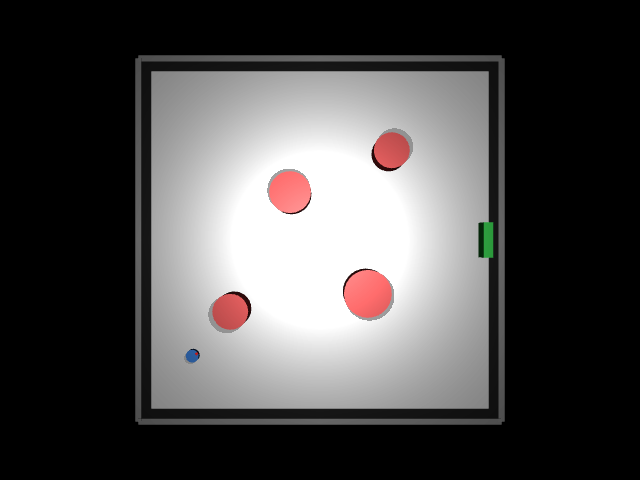

In [10]:
from PIL import Image
from IPython.display import display

with mujoco.Renderer(
    model,
    height=480,
    width=640
) as renderer:

    renderer.update_scene(data, camera="overhead")

    room_image = renderer.render().copy()

display(Image.fromarray(room_image))

In [ ]:
import mujoco
import numpy as np

# Reset robot to starting position
mujoco.mj_resetData(model, data)

x, y, theta = cfg.X0_NOMINAL
data.qpos[:] = [x, y, theta]

mujoco.mj_forward(model, data)

frames = []
trajectory = []

dt = model.opt.timestep
duration = 8.0
steps = int(duration / dt)

with mujoco.Renderer(
    model, height=480, width=640
) as renderer:

    for i in range(steps):

        t = i * dt

        # Movement sequence
        if t < 3.0:
            v = 0.15
            omega = 0.0

        elif t < 5.0:
            v = 0.0
            omega = 0.5

        else:
            v = 0.15
            omega = 0.0

        # Differential-drive kinematics
        x += v * np.cos(theta) * dt
        y += v * np.sin(theta) * dt
        theta += omega * dt

        # Update planar MuJoCo joints
        data.qpos[:] = [x, y, theta]

        mujoco.mj_forward(model, data)

        trajectory.append([x, y, theta])

        # Capture video at 20 FPS
        if i % 5 == 0:
            renderer.update_scene(
                data,
                camera="overhead"
            )

            frames.append(
                renderer.render().copy()
            )

trajectory = np.array(trajectory)

print("Simulation completed!")
print("Final position:", trajectory[-1, :2])
print("Final heading:",
      round(np.degrees(theta), 2), "degrees")
print("Frames:", len(frames))

Simulation completed!
Final position: [-1.77325611 -1.33538576]
Final heading: 85.94 degrees
Frames: 160


In [ ]:
import imageio
from IPython.display import Video, display

imageio.mimsave(
    "trackA_mujoco_test.mp4",
    frames,
    fps=20,
    macro_block_size=16
)

display(Video("trackA_mujoco_test.mp4", embed=True))

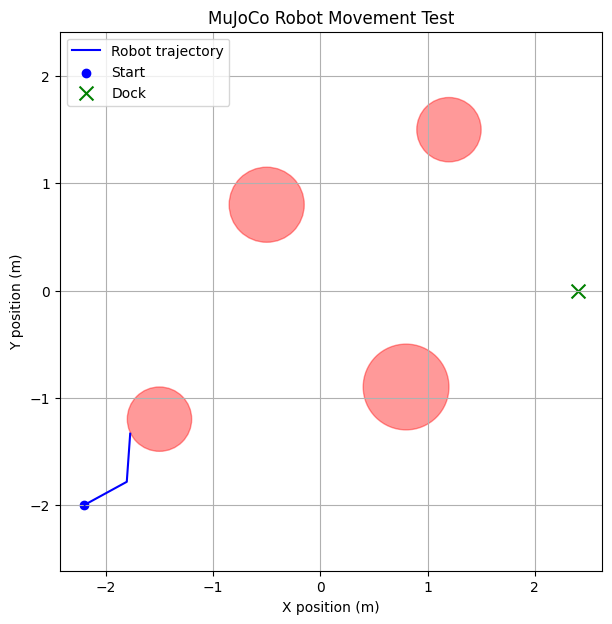

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

# Room boundaries
xmin, xmax, ymin, ymax = cfg.room

plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)

# Obstacles
for ox, oy, radius in cfg.obstacles:
    circle = plt.Circle(
        (ox, oy),
        radius,
        color="red",
        alpha=0.4
    )
    plt.gca().add_patch(circle)

# Robot trajectory
plt.plot(
    trajectory[:, 0],
    trajectory[:, 1],
    "b-",
    label="Robot trajectory"
)

# Starting position
plt.scatter(
    cfg.X0_NOMINAL[0],
    cfg.X0_NOMINAL[1],
    color="blue",
    marker="o",
    label="Start"
)

# Docking position
plt.scatter(
    cfg.dock_pose[0],
    cfg.dock_pose[1],
    color="green",
    marker="x",
    s=100,
    label="Dock"
)

plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")
plt.title("MuJoCo Robot Movement Test")

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.show()

In [ ]:
from tb3nav.planner import build_reference

# Generate a path using the existing A* planner
path, clearance = build_reference(
    cfg,
    np.array(cfg.X0_NOMINAL[:2]),
    cfg.X0_NOMINAL[2]
)

print("Path generated successfully!")
print("Path length:", round(path.s_end, 2), "m")
print("Minimum obstacle clearance:",
      round(clearance, 3), "m")

Path generated successfully!
Path length: 5.52 m
Minimum obstacle clearance: 0.408 m


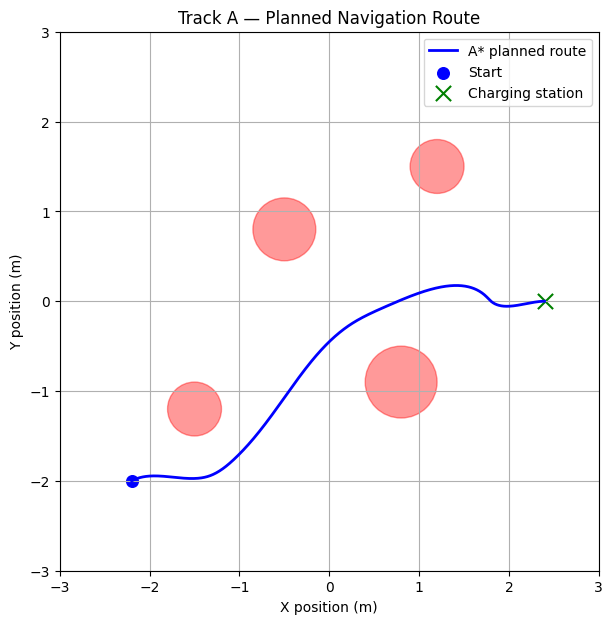

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7))

# Room
xmin, xmax, ymin, ymax = cfg.room
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# Obstacles
for ox, oy, radius in cfg.obstacles:
    ax.add_patch(
        plt.Circle(
            (ox, oy),
            radius,
            color="red",
            alpha=0.4
        )
    )

# Planned route
ax.plot(
    path.x,
    path.y,
    "b-",
    linewidth=2,
    label="A* planned route"
)

# Start
ax.scatter(
    cfg.X0_NOMINAL[0],
    cfg.X0_NOMINAL[1],
    color="blue",
    marker="o",
    s=70,
    label="Start"
)

# Dock
ax.scatter(
    cfg.dock_pose[0],
    cfg.dock_pose[1],
    color="green",
    marker="x",
    s=120,
    label="Charging station"
)

ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_title("Track A — Planned Navigation Route")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.show()

In [ ]:
print("=== PLANNER CHECK ===")

print("Path points:", len(path.x))
print("Start:", (path.x[0], path.y[0]))
print("End:", (path.x[-1], path.y[-1]))
print("Path length:", round(path.s_end, 2), "m")
print("Clearance:", round(clearance, 3), "m")

if clearance > cfg.robot_radius:
    print("PASS: Planned path clears obstacle geometry.")
else:
    print("WARNING: Planned path may be too close to obstacles.")

=== PLANNER CHECK ===
Path points: 1084
Start: (np.float64(-2.2), np.float64(-2.0))
End: (np.float64(2.3955633040464033), np.float64(-2.0567239721769326e-05))
Path length: 5.52 m
Clearance: 0.408 m
PASS: Planned path clears obstacle geometry.


In [ ]:
import numpy as np
import mujoco

# Reset robot
mujoco.mj_resetData(model, data)

x, y, theta = map(float, cfg.X0_NOMINAL)
data.qpos[:3] = [x, y, theta]
mujoco.mj_forward(model, data)

# Planned route from your ZIP
route = np.column_stack((path.x, path.y))

# Simulation settings
dt = model.opt.timestep
max_time = 90.0
steps = int(max_time / dt)

speed = 0.15
lookahead = 0.30
goal_tolerance = 0.10

frames = []
actual_trajectory = []
reached_goal = False

# Progress along planned route
target_index = 0

with mujoco.Renderer(
    model, height=480, width=640
) as renderer:

    for i in range(steps):

        # Advance lookahead point along the route
        while target_index < len(route) - 1:
            distance_to_point = np.hypot(
                route[target_index, 0] - x,
                route[target_index, 1] - y
            )

            if distance_to_point >= lookahead:
                break

            target_index += 1

        target = route[target_index]

        # Distance to docking position
        goal_distance = np.hypot(
            x - cfg.dock_pose[0],
            y - cfg.dock_pose[1]
        )

        if goal_distance < goal_tolerance:
            reached_goal = True
            break

        # Calculate desired heading
        dx = target[0] - x
        dy = target[1] - y

        desired_heading = np.arctan2(dy, dx)

        heading_error = (
            desired_heading - theta + np.pi
        ) % (2 * np.pi) - np.pi

        # Basic path-following controller
        omega = np.clip(
            2.0 * heading_error,
            -0.8,
            0.8
        )

        # Reduce speed for large heading errors
        v = speed * max(
            0.0,
            np.cos(heading_error)
        )

        # Slow near the dock
        if goal_distance < 0.5:
            v = min(v, 0.5 * goal_distance)

        # Update differential-drive kinematics
        x += v * np.cos(theta) * dt
        y += v * np.sin(theta) * dt
        theta += omega * dt

        # Update MuJoCo robot
        data.qpos[:3] = [x, y, theta]
        mujoco.mj_forward(model, data)

        actual_trajectory.append([x, y, theta])

        # Capture video at 10 FPS
        if i % max(1, round(0.1 / dt)) == 0:
            renderer.update_scene(
                data,
                camera="overhead"
            )
            frames.append(
                renderer.render().copy()
            )

actual_trajectory = np.array(actual_trajectory)

print("=== PATH FOLLOWING RESULTS ===")
print("Reached goal:", reached_goal)
print("Final position:", round(x, 3), round(y, 3))
print("Goal distance:", round(goal_distance, 3), "m")
print("Simulation time:", round(i * dt, 2), "s")


=== PATH FOLLOWING RESULTS ===
Reached goal: True
Final position: 2.301 -0.007
Goal distance: 0.1 m
Simulation time: 36.59 s


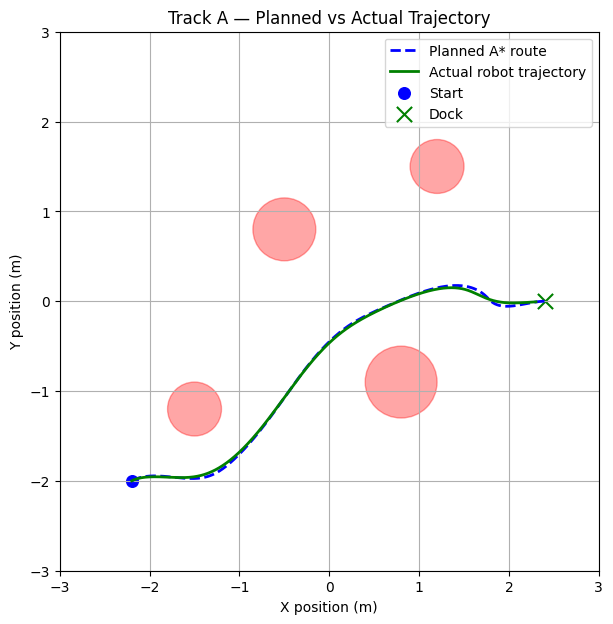

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7))

# Plot obstacles
for ox, oy, radius in cfg.obstacles:
    ax.add_patch(
        plt.Circle(
            (ox, oy),
            radius,
            color="red",
            alpha=0.35
        )
    )

# Planned A* route
ax.plot(
    path.x,
    path.y,
    "b--",
    linewidth=2,
    label="Planned A* route"
)

# Actual simulated robot trajectory
ax.plot(
    actual_trajectory[:, 0],
    actual_trajectory[:, 1],
    "g-",
    linewidth=2,
    label="Actual robot trajectory"
)

# Start and dock
ax.scatter(
    cfg.X0_NOMINAL[0],
    cfg.X0_NOMINAL[1],
    color="blue",
    s=70,
    label="Start"
)

ax.scatter(
    cfg.dock_pose[0],
    cfg.dock_pose[1],
    color="green",
    marker="x",
    s=120,
    label="Dock"
)

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect("equal")

ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_title("Track A — Planned vs Actual Trajectory")

ax.grid(True)
ax.legend()

plt.show()


In [ ]:
# Calculate minimum clearance to circular obstacles
min_clearance = float("inf")

for ox, oy, radius in cfg.obstacles:
    distances = np.hypot(
        actual_trajectory[:, 0] - ox,
        actual_trajectory[:, 1] - oy
    )

    clearance = np.min(distances) - radius
    min_clearance = min(min_clearance, clearance)

# Account for the robot's physical radius
robot_clearance = min_clearance - cfg.robot_radius

# Final heading error
heading_error = (
    theta - cfg.dock_pose[2] + np.pi
) % (2 * np.pi) - np.pi

print("=== NAVIGATION CHECK ===")
print("Minimum robot clearance:",
      round(robot_clearance, 3), "m")

print("Final position error:",
      round(np.hypot(
          x - cfg.dock_pose[0],
          y - cfg.dock_pose[1]
      ), 3), "m")

print("Final heading error:",
      round(np.degrees(heading_error), 2), "degrees")

print("Reached docking position:", reached_goal)

if robot_clearance > 0:
    print("Obstacle clearance: PASS")
else:
    print("Obstacle clearance: FAIL")

=== NAVIGATION CHECK ===
Minimum robot clearance: 0.281 m
Final position error: 0.1 m
Final heading error: 4.02 degrees
Reached docking position: True
Obstacle clearance: PASS


In [ ]:
import imageio
from IPython.display import Video, display

imageio.mimsave(
    "trackA_path_following.mp4",
    frames,
    fps=10,
    macro_block_size=16
)

display(Video("trackA_path_following.mp4", embed=True))

In [ ]:
import inspect

from tb3nav.pipeline import simulate_lqg
from tb3nav.mujoco_adapter import MuJoCoTurtleBot

print("=== EXISTING PIPELINE ===")
print(inspect.getsource(simulate_lqg))

print("\n=== MUJOCO ADAPTER ===")
print(inspect.getsource(MuJoCoTurtleBot))

=== EXISTING PIPELINE ===
def simulate_lqg(cfg=None, ctrl="lqi", seed=0, sim_kw=None, no_updates=False):
    """The EKF estimate drives the controller. x_true is kept for the log only: if it appeared in the control
    path the loop would not be LQG (see the control block below)."""
    cfg = cfg or Config()
    sim, path, clr, x_nom, P0 = _setup(cfg, seed, sim_kw or {})
    controller = _controller(cfg, ctrl); controller.reset()
    ec, cam = EKFConfig(cfg), make_camera(cfg)
    icp = ICPOdomSource(cfg, sim.lidar_angles) if cfg.odom_source == "icp" else None
    sv, sw = ((cfg.icp_sigma_v, cfg.icp_sigma_w) if icp else (cfg.ekf_sigma_v, cfg.ekf_sigma_w))
    xh, P = x_nom.copy(), P0.copy()
    log, u, idx, hold, reached = _empty_log(), (0.0, 0.0), 0, 0, False
    for k in range(int(cfg.t_max / cfg.T)):
        m = sim.step(u)                                            # robot moves, sensors are read
        odom = icp(m.lidar, m.odom)[0] if icp else m.odom          # wheel encoders or 

In [ ]:
from tb3nav.sim import Sim2D, Measurements

print("=== SIMULATOR STEP ===")
print(inspect.getsource(Sim2D.step))

print("\n=== MEASUREMENT STRUCTURE ===")
print(Measurements.__annotations__)

=== SIMULATOR STEP ===
    def step(self, u):
        c, T = self.cfg, self.cfg.T
        v_cmd = float(np.clip(u[0], -c.v_max, c.v_max))
        w_cmd = float(np.clip(u[1], -c.omega_max, c.omega_max))
        # worn wheel: constant yaw-rate bias that grows with speed (NOT seen by the encoders)
        self.d_wheel = v_cmd * self.wheel_error / c.wheel_sep
        v = v_cmd * self.slip[0] + self.rng_robot.normal(0, c.act_sigma_v)
        w = w_cmd * self.slip[1] + self.d_wheel + self.rng_robot.normal(0, c.act_sigma_w)
        if self.kick_std > 0 and self.rng_robot.random() < self.kick_rate * T:
            self._x[2] += self.rng_robot.normal(0, self.kick_std)
        th_m = self._x[2] + 0.5 * w * T
        self._x += np.array([v * T * np.cos(th_m), v * T * np.sin(th_m), w * T])
        self._x[2] = wrap(self._x[2])
        self.t += T
        self._collision()
        odom = (v_cmd + self.rng_sensor.normal(0, self.s * c.enc_sigma_v),
                w_cmd + self.rng_sensor.normal(0, se

In [ ]:
from tb3nav.ekf import EKFConfig, ekf_step
from tb3nav.control import LQRController, LQIController

ekf_cfg = EKFConfig(cfg)
controller = LQRController(cfg)
controller.reset()

print("EKF imported successfully!")
print("LQR controller imported successfully!")
print("MuJoCo environment available:", model is not None)
print("Planned route available:", path is not None)

EKF imported successfully!
LQR controller imported successfully!
MuJoCo environment available: True
Planned route available: True


In [36]:
import numpy as np
import mujoco

from tb3nav.sim import Measurements
from tb3nav.mujoco_adapter import (
    wheels_from_cmd,
    odom_from_wheels
)
from tb3nav.utils import wrap

class PlanarMuJoCoAdapter:

    def __init__(self, cfg, model, data):
        self.cfg = cfg
        self.model = model
        self.data = data

        self.t = 0.0
        self.lidar_angles = np.linspace(
            -np.pi, np.pi,
            cfg.lidar_n,
            endpoint=False
        )

        self.rng = np.random.default_rng(42)

        self.reset()

    def reset(self):
        mujoco.mj_resetData(self.model, self.data)

        self.x = np.array(
            self.cfg.X0_NOMINAL,
            dtype=float
        )

        self.data.qpos[:3] = self.x
        mujoco.mj_forward(self.model, self.data)

        self.t = 0.0

    def step(self, u):
        v, omega = u

        v = float(np.clip(
            v, -self.cfg.v_max, self.cfg.v_max
        ))

        omega = float(np.clip(
            omega,
            -self.cfg.omega_max,
            self.cfg.omega_max
        ))

        dt = self.cfg.T

        # Differential-drive motion
        theta_mid = self.x[2] + 0.5 * omega * dt

        self.x[0] += v * np.cos(theta_mid) * dt
        self.x[1] += v * np.sin(theta_mid) * dt
        self.x[2] = wrap(self.x[2] + omega * dt)

        # Update MuJoCo robot
        self.data.qpos[:3] = self.x
        mujoco.mj_forward(self.model, self.data)

        self.t += dt

        # Virtual wheel encoder readings
        wl, wr = wheels_from_cmd(v, omega)

        wl += self.rng.normal(0, 0.02)
        wr += self.rng.normal(0, 0.02)

        odom = odom_from_wheels(wl, wr)

        # Sensors not connected yet
        corners = {}
        lidar = np.full(
            self.cfg.lidar_n,
            self.cfg.lidar_max
        )

        return Measurements(
            t=self.t,
            odom=odom,
            corners=corners,
            lidar=lidar
        )

    def ground_truth(self):
        # Evaluation only
        return self.x.copy()

print("Planar MuJoCo adapter created!")


Planar MuJoCo adapter created!


In [54]:
sim = PlanarMuJoCoAdapter(cfg, model, data)

print("=== ADAPTER TEST ===")

for i in range(30):
    m = sim.step((0.15, 0.0))

print("Simulation time:", round(m.t, 2), "s")
print("Wheel odometry:", m.odom)
print("Robot position:", sim.ground_truth())
print("LiDAR readings:", len(m.lidar))
print("Camera detections:", len(m.corners))


=== ADAPTER TEST ===
Simulation time: 3.0 s
Wheel odometry: (0.15003380758883642, 0.007565701564924504)
Robot position: [-1.80508785 -1.78425851  0.5       ]
LiDAR readings: 360
Camera detections: 0


In [ ]:
from tb3nav.ekf import EKFConfig, ekf_step

sim.reset()

ec = EKFConfig(cfg)

xh = np.array(cfg.X0_NOMINAL, dtype=float)
P = np.diag(np.array(cfg.P0_std) ** 2)

estimated_positions = []
true_positions = []

for i in range(100):

    m = sim.step((0.12, 0.0))

    # No camera measurements yet
    Z = []

    xh, P, nis = ekf_step(
        xh, P, m.odom, Z, ec
    )

    estimated_positions.append(xh.copy())
    true_positions.append(
        sim.ground_truth()
    )

estimated_positions = np.array(estimated_positions)
true_positions = np.array(true_positions)

print("=== EKF PREDICTION TEST ===")
print("True final position:", true_positions[-1, :2])
print("Estimated final position:", estimated_positions[-1, :2])

error = np.linalg.norm(
    true_positions[-1, :2] -
    estimated_positions[-1, :2]
)

print("Position error:", round(error, 4), "m")
print("Covariance diagonal:", np.diag(P))


=== EKF PREDICTION TEST ===
True final position: [-1.14690093 -1.42468935]
Estimated final position: [-1.1477748  -1.42421227]
Position error: 0.001 m
Covariance diagonal: [0.04797675 0.06546922 0.02961095]


In [43]:
import numpy as np
import mujoco

def simulate_lidar(model, data, cfg, pose, noise_std=0.01):
    """
    Simulate 2D LiDAR against the MuJoCo room's
    circular obstacles and axis-aligned walls.
    """

    x, y, theta = map(float, pose)
    angles = np.linspace(
        -np.pi, np.pi, cfg.lidar_n, endpoint=False
    )

    ranges = np.full(cfg.lidar_n, cfg.lidar_max)

    # Read obstacle locations and sizes from MuJoCo
    obstacles = []

    for i in range(len(cfg.obstacles)):
        gid = mujoco.mj_name2id(
            model, mujoco.mjtObj.mjOBJ_GEOM,
            f"obstacle_{i}"
        )
        if gid < 0:
            raise ValueError(f"Missing obstacle_{i}")

        ox, oy = data.geom_xpos[gid, :2]
        radius = model.geom_size[gid, 0]
        obstacles.append((ox, oy, radius))

    xmin, xmax, ymin, ymax = cfg.room

    for i, angle in enumerate(angles):
        a = theta + angle
        dx, dy = np.cos(a), np.sin(a)

        best = float(cfg.lidar_max)

        # Ray intersections with circular obstacles
        for ox, oy, radius in obstacles:
            fx, fy = x - ox, y - oy
            b = fx * dx + fy * dy
            c = fx**2 + fy**2 - radius**2
            disc = b**2 - c

            if disc >= 0:
                root = np.sqrt(disc)
                hits = [-b - root, -b + root]
                positive = [t for t in hits if t >= 0]
                if positive:
                    best = min(best, min(positive))

        # Ray intersections with room walls
        if abs(dx) > 1e-9:
            for wall_x in (xmin, xmax):
                t = (wall_x - x) / dx
                yy = y + t * dy
                if t >= 0 and ymin <= yy <= ymax:
                    best = min(best, t)

        if abs(dy) > 1e-9:
            for wall_y in (ymin, ymax):
                t = (wall_y - y) / dy
                xx = x + t * dx
                if t >= 0 and xmin <= xx <= xmax:
                    best = min(best, t)

        ranges[i] = best

    # Add small measurement noise
    ranges += np.random.normal(
        0, noise_std, size=len(ranges)
    )

    return np.clip(ranges, 0, cfg.lidar_max)

print("LiDAR function created!")


LiDAR function created!


In [ ]:
sim.reset()

pose = sim.ground_truth()

lidar = simulate_lidar(
    model, data, cfg, pose
)

print("=== LIDAR TEST ===")
print("Number of rays:", len(lidar))
print("Minimum distance:", round(np.min(lidar), 3), "m")
print("Maximum distance:", round(np.max(lidar), 3), "m")
print("Average distance:", round(np.mean(lidar), 3), "m")

=== LIDAR TEST ===
Number of rays: 360
Minimum distance: 0.757 m
Maximum distance: 3.5 m
Average distance: 1.724 m


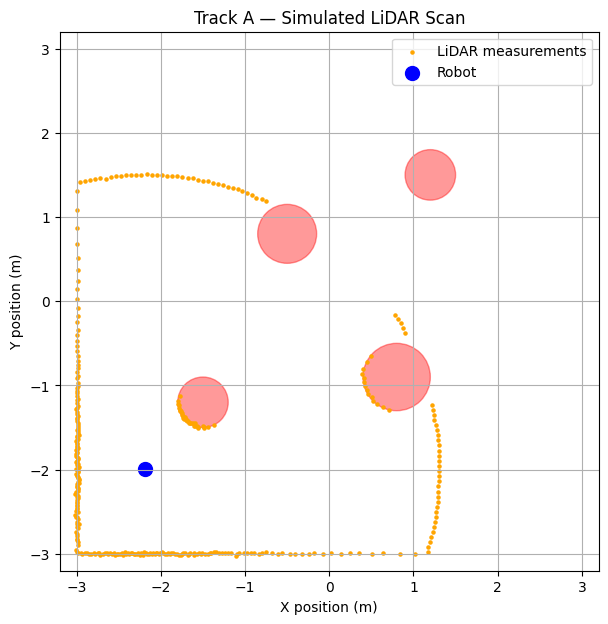

In [ ]:
import matplotlib.pyplot as plt

pose = sim.ground_truth()
x, y, theta = pose

angles = np.linspace(
    -np.pi, np.pi, len(lidar), endpoint=False
)

world_angles = angles + theta

scan_x = x + lidar * np.cos(world_angles)
scan_y = y + lidar * np.sin(world_angles)

fig, ax = plt.subplots(figsize=(7, 7))

for ox, oy, radius in cfg.obstacles:
    ax.add_patch(
        plt.Circle(
            (ox, oy), radius,
            color="red", alpha=0.4
        )
    )

ax.scatter(
    scan_x, scan_y,
    s=5, color="orange",
    label="LiDAR measurements"
)

ax.scatter(
    x, y,
    color="blue", s=100,
    label="Robot"
)

ax.set_xlim(-3.2, 3.2)
ax.set_ylim(-3.2, 3.2)
ax.set_aspect("equal")
ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_title("Track A — Simulated LiDAR Scan")
ax.grid(True)
ax.legend()

plt.show()


In [53]:
class PlanarMuJoCoWithLiDAR(PlanarMuJoCoAdapter):

    def step(self, u):
        # Run existing motion and encoder simulation
        m = super().step(u)

        # Obtain simulated LiDAR scan
        lidar = simulate_lidar(
            self.model,
            self.data,
            self.cfg,
            self.x
        )

        return Measurements(
            t=m.t,
            odom=m.odom,
            corners=m.corners,
            lidar=lidar
        )

# Create updated simulator
sim = PlanarMuJoCoWithLiDAR(cfg, model, data)

# Test one movement step
m = sim.step((0.1, 0.0))

print("=== UPDATED ADAPTER ===")
print("Time:", m.t)
print("Odometry:", m.odom)
print("LiDAR rays:", len(m.lidar))
print("Nearest obstacle/wall:", round(np.min(m.lidar), 3), "m")
print("Camera detections:", len(m.corners))


=== UPDATED ADAPTER ===
Time: 0.1
Odometry: (0.09975736188125961, -0.005546892392229058)
LiDAR rays: 360
Nearest obstacle/wall: 0.748 m
Camera detections: 0


In [ ]:
import inspect
import tb3nav.vision as vision
import tb3nav.ekf as ekf

print("=== VISION FUNCTIONS ===")

for name, obj in inspect.getmembers(vision, inspect.isfunction):
    if obj.__module__ == vision.__name__:
        print(name, inspect.signature(obj))

print("\n=== EKF FUNCTIONS ===")

for name, obj in inspect.getmembers(ekf, inspect.isfunction):
    if obj.__module__ == ekf.__name__:
        print(name, inspect.signature(obj))

=== VISION FUNCTIONS ===
detect_pose (cfg, cam, corners_px)
marker_measurement (cfg, T_BC, T_C_M)
measurements_from_corners (cfg, cam, corners)

=== EKF FUNCTIONS ===
ekf_step (xh, P, u, Z, ec, sigma_v=None, sigma_w=None)


In [ ]:
from tb3nav.config import Config

cfg = Config()

print("=== CAMERA AND MARKER SETTINGS ===")

for name, value in vars(cfg).items():
    if any(word in name.lower() for word in [
        "camera", "aruco", "marker",
        "tag", "intrinsic", "fov"
    ]):
        print(f"{name}: {value}")

=== CAMERA AND MARKER SETTINGS ===
marker_size: 0.3
marker_height: 0.15


OpenCV version: 4.14.0
ArUco available: True


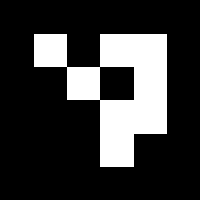

In [ ]:
import cv2

print("OpenCV version:", cv2.__version__)
print("ArUco available:", hasattr(cv2, "aruco"))

if hasattr(cv2, "aruco"):
    dictionary = cv2.aruco.getPredefinedDictionary(
        cv2.aruco.DICT_4X4_50
    )

    marker = cv2.aruco.generateImageMarker(
        dictionary, 0, 200
    )

    from PIL import Image
    from IPython.display import display

    display(Image.fromarray(marker))

In [ ]:
from tb3nav.ekf import ekf_step
from tb3nav.sim import Measurements, Sim2D

print("=== EKF STEP ===")
print(inspect.getsource(ekf_step))

print("\n=== SIMULATOR MEASUREMENT GENERATION ===")
print(inspect.getsource(Sim2D.step))

print("\n=== MEASUREMENT FIELDS ===")
print(Measurements.__annotations__)

=== EKF STEP ===
def ekf_step(xh, P, u, Z, ec, sigma_v=None, sigma_w=None):
    """xh (3,), P (3x3), u = odometry (v, w), Z = (M,3) marker measurements with NaN rows if not seen.
    nis entries are (nis, dof, accepted)."""
    cfg, T = ec.cfg, ec.T
    sv = cfg.ekf_sigma_v if sigma_v is None else sigma_v
    sw = cfg.ekf_sigma_w if sigma_w is None else sigma_w
    # ---- predict with the odometry actually measured ----
    F = F_uni(xh, u, T)
    Qd = Q_D(xh, u, T, sv, sw, cfg.q_floor)
    xh = f_uni(xh, u, T)
    P = F @ P @ F.T + Qd
    # ---- update, one marker at a time ----
    dims = 3 if cfg.meas_mode == "pose" else 2
    nis = []
    for i, zi in enumerate(Z):
        if not np.all(np.isfinite(zi[:dims])):
            continue                                           # marker not seen / dropped
        zhat, H = h_marker(xh, cfg.landmarks[i], cfg.meas_mode)   # Jacobian at the CURRENT estimate
        nu = zi[:dims] - zhat
        nu[1:] = wrap(nu[1:])
        R = ec.noise.R(

In [ ]:
print("=== CAMERA CONFIGURATION ===")

for name, value in vars(cfg).items():
    print(f"{name}: {value}")

=== CAMERA CONFIGURATION ===
T: 0.1
t_max: 150.0
v_ref: 0.15
v_max: 0.22
omega_max: 2.84
robot_radius: 0.11
wheel_sep: 0.16
wheel_radius: 0.033
seed: 41014
room: (-3.0, 3.0, -3.0, 3.0)
obstacles: ((-0.5, 0.8, 0.35), (0.8, -0.9, 0.4), (-1.5, -1.2, 0.3), (1.2, 1.5, 0.3))
landmarks: {0: (3.0, 0.0, 3.141592653589793), 1: (-3.0, 1.5, 0.0), 2: (0.0, 3.0, -1.5707963267948966), 3: (0.0, -3.0, 1.5707963267948966), 4: (3.0, -2.0, 3.141592653589793), 5: (-3.0, -1.5, 0.0), 6: (-2.0, 3.0, -1.5707963267948966), 7: (2.0, 3.0, -1.5707963267948966), 8: (-2.0, -3.0, 1.5707963267948966), 9: (2.0, -3.0, 1.5707963267948966), 10: (3.0, 2.0, 3.141592653589793)}
marker_size: 0.3
marker_height: 0.15
dock_pose: (2.4, 0.0, 0.0)
approach_pt: (1.8, 0.0)
X0_NOMINAL: (-2.2, -2.0, 0.5)
P0_std: (0.2, 0.2, np.float64(0.13962634015954636))
f_px: 320.0
image_size: (640, 480)
cam_in_base: (0.05, 0.0, 0.15)
cam_range: 5.0
cam_max_view_angle: 1.2217304763960306
sigma_px: 0.5
p_drop: 0.05
px_margin: 5.0
enc_sigma_v: 0.01
enc

In [ ]:
import inspect
from tb3nav.vision import (
    detect_pose,
    marker_measurement,
    measurements_from_corners
)

print(inspect.getsource(measurements_from_corners))
print(inspect.getsource(marker_measurement))

def measurements_from_corners(cfg, cam, corners):
    """dict id -> corners  =>  (M, 3) array with NaN rows for markers not seen (A3 convention)."""
    T_BC = T_B_C(cfg)
    Z = np.full((len(cfg.landmarks), 3), np.nan)
    for i, c in corners.items():
        T = detect_pose(cfg, cam, c)
        if T is not None:
            Z[i] = marker_measurement(cfg, T_BC, T)
    return Z

def marker_measurement(cfg, T_BC, T_C_M):
    """T_C_M (marker in camera) -> (range, bearing, psi) in the BASE frame (frame management)."""
    T_B_M = T_BC * T_C_M
    p, n = T_B_M.t, T_B_M.R[:, 2]
    return np.array([np.hypot(p[0], p[1]), np.arctan2(p[1], p[0]), np.arctan2(n[1], n[0])])



In [ ]:
from tb3nav.sim import Sim2D
import inspect

print(inspect.getsource(Sim2D._camera))

    def _camera(self):
        c = self.cfg
        if any(t0 <= self.t < t1 for t0, t1 in self.blackout):
            return {}
        x, y, th = self._x
        T_W_C = pose2SE3(self._x) * self._TBC
        T_C_W = T_W_C.inv()
        W, H = c.image_size
        out = {}
        for i, (mx, my, nu) in c.landmarks.items():
            dx, dy = mx - x, my - y
            r = np.hypot(dx, dy)
            if r > c.cam_range:
                continue
            # marker must face the robot: angle between its normal and the line of sight
            if np.cos(nu) * (-dx) / r + np.sin(nu) * (-dy) / r < np.cos(c.cam_max_view_angle):
                continue
            Pc = T_C_W * self._Pw[i]
            if np.any(Pc[2] < 0.1) or self._occluded((x, y), (mx, my)):
                continue
            uv = self.cam.project_point(self._Pw[i], pose=T_W_C)            # 2x4 pixels
            if (uv[0].min() < c.px_margin or uv[0].max() > W - c.px_margin or
                    uv[1].min() < c.p

=== ARUCO DETECTION TEST ===
Detected IDs: [[0]]
Number of detections: 1


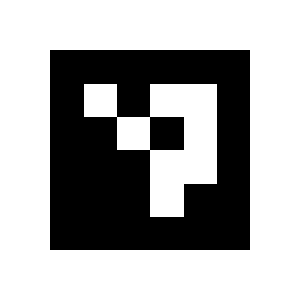

In [ ]:
import cv2
import numpy as np
from PIL import Image
from IPython.display import display

# ArUco dictionary
dictionary = cv2.aruco.getPredefinedDictionary(
    cv2.aruco.DICT_4X4_50
)

# Generate marker ID 0
marker = cv2.aruco.generateImageMarker(
    dictionary,
    0,
    200
)

# Add white border around the marker
canvas = np.full(
    (300, 300),
    255,
    dtype=np.uint8
)

canvas[50:250, 50:250] = marker

# Detect the marker
detector = cv2.aruco.ArucoDetector(
    dictionary,
    cv2.aruco.DetectorParameters()
)

corners, ids, rejected = detector.detectMarkers(
    canvas
)

print("=== ARUCO DETECTION TEST ===")
print("Detected IDs:", ids)
print("Number of detections:", len(corners))

# Display image
display(Image.fromarray(canvas))

In [ ]:
from tb3nav.sim import Sim2D
import inspect

print(inspect.signature(Sim2D))
print(inspect.getsource(Sim2D.__init__))

(cfg, x0, seed=0, noise_scale=1.0, wheel_error=None, slip=(1.0, 1.0), kick_std=0.0, kick_rate=0.2, blackout=())
    def __init__(self, cfg, x0, seed=0, noise_scale=1.0, wheel_error=None, slip=(1.0, 1.0),
                 kick_std=0.0, kick_rate=0.2, blackout=()):
        self.cfg = cfg
        self.rng_robot, self.rng_sensor = np.random.default_rng(seed), np.random.default_rng(seed + 1)
        self._x = np.array(x0, float)
        self.t, self.s = 0.0, noise_scale
        self.wheel_error = cfg.wheel_error if wheel_error is None else wheel_error
        self.slip, self.kick_std, self.kick_rate, self.blackout = slip, kick_std, kick_rate, blackout
        self.lidar_angles = np.linspace(-np.pi, np.pi, cfg.lidar_n, endpoint=False)
        self.collided, self.min_clearance = False, np.inf
        self.cam = make_camera(cfg)
        self._TBC = T_B_C(cfg)
        self._TWM = {i: T_W_M(cfg, i) for i in cfg.landmarks}
        self._obj = marker_corners_M(cfg)
        self._Pw = {i: (T * self

In [ ]:
from tb3nav.vision import measurements_from_corners

print(inspect.getsource(measurements_from_corners))

def measurements_from_corners(cfg, cam, corners):
    """dict id -> corners  =>  (M, 3) array with NaN rows for markers not seen (A3 convention)."""
    T_BC = T_B_C(cfg)
    Z = np.full((len(cfg.landmarks), 3), np.nan)
    for i, c in corners.items():
        T = detect_pose(cfg, cam, c)
        if T is not None:
            Z[i] = marker_measurement(cfg, T_BC, T)
    return Z



In [ ]:
import numpy as np

from tb3nav.ekf import EKFConfig, ekf_step

ec = EKFConfig(cfg)

# Initial estimated state
xh = np.array(cfg.X0_NOMINAL, dtype=float)

# Initial covariance
P = np.diag(np.array(cfg.P0_std) ** 2)

# No visible markers initially
Z = np.full(
    (len(cfg.landmarks), 3),
    np.nan
)

# Example wheel odometry
u = (0.1, 0.0)

xh, P, nis = ekf_step(
    xh, P, u, Z, ec
)

print("=== EKF MEASUREMENT TEST ===")
print("Estimated state:", xh)
print("Covariance diagonal:", np.diag(P))
print("Accepted marker measurements:", len(nis))

=== EKF MEASUREMENT TEST ===
Estimated state: [-2.19122417 -1.99520574  0.5       ]
Covariance diagonal: [0.04000453 0.04000342 0.01959667]
Accepted marker measurements: 0


In [ ]:
import inspect

from tb3nav.sim import Sim2D

print("=== SIM2D INITIALISATION ===")
print(inspect.getsource(Sim2D.__init__))

=== SIM2D INITIALISATION ===
    def __init__(self, cfg, x0, seed=0, noise_scale=1.0, wheel_error=None, slip=(1.0, 1.0),
                 kick_std=0.0, kick_rate=0.2, blackout=()):
        self.cfg = cfg
        self.rng_robot, self.rng_sensor = np.random.default_rng(seed), np.random.default_rng(seed + 1)
        self._x = np.array(x0, float)
        self.t, self.s = 0.0, noise_scale
        self.wheel_error = cfg.wheel_error if wheel_error is None else wheel_error
        self.slip, self.kick_std, self.kick_rate, self.blackout = slip, kick_std, kick_rate, blackout
        self.lidar_angles = np.linspace(-np.pi, np.pi, cfg.lidar_n, endpoint=False)
        self.collided, self.min_clearance = False, np.inf
        self.cam = make_camera(cfg)
        self._TBC = T_B_C(cfg)
        self._TWM = {i: T_W_M(cfg, i) for i in cfg.landmarks}
        self._obj = marker_corners_M(cfg)
        self._Pw = {i: (T * self._obj.T) for i, T in self._TWM.items()}      # 3x4 corners in W
        self.d_whee

In [ ]:
import numpy as np

from tb3nav.sim import Sim2D
from tb3nav.vision import measurements_from_corners

# Create original simulator for camera testing
camera_sim = Sim2D(
    cfg,
    x0=cfg.X0_NOMINAL,
    seed=42,
    noise_scale=1.0,
    wheel_error=0.0
)

print("=== CAMERA INITIALISATION ===")
print("Camera created:", camera_sim.cam is not None)
print("Number of landmarks:", len(cfg.landmarks))
print("Camera resolution:", cfg.image_size)
print("Measurement mode:", cfg.meas_mode)

=== CAMERA INITIALISATION ===
Camera created: True
Number of landmarks: 11
Camera resolution: (640, 480)
Measurement mode: rb


In [ ]:
camera_sim = Sim2D(
    cfg,
    x0=cfg.X0_NOMINAL,
    seed=42,
    wheel_error=0.0
)

detected_markers = set()
first_detection = None

for i in range(100):

    # Rotate slowly to search for markers
    m = camera_sim.step((0.0, 0.3))

    if len(m.corners) > 0:
        detected_markers.update(m.corners.keys())

        if first_detection is None:
            first_detection = m.corners

print("=== CAMERA OBSERVATION TEST ===")
print("Detected marker IDs:", sorted(detected_markers))
print("Number of unique markers:", len(detected_markers))

if first_detection is not None:
    print("Camera observations generated successfully!")
else:
    print("No markers detected. Check visibility and camera settings.")

=== CAMERA OBSERVATION TEST ===
Detected marker IDs: [5]
Number of unique markers: 1
Camera observations generated successfully!


In [ ]:
if first_detection is not None:

    Z = measurements_from_corners(
        cfg,
        camera_sim.cam,
        first_detection
    )

    print("=== CAMERA MEASUREMENT CONVERSION ===")
    print("Measurement array shape:", Z.shape)

    for marker_id in sorted(first_detection.keys()):
        print(
            f"Marker {marker_id}:",
            np.round(Z[marker_id], 3)
        )

else:
    print("No camera observations available for conversion.")


=== CAMERA MEASUREMENT CONVERSION ===
Measurement array shape: (11, 3)
Marker 5: [ 0.939  0.585 -1.987]


In [ ]:
from tb3nav.ekf import EKFConfig, ekf_step

camera_sim = Sim2D(
    cfg,
    x0=cfg.X0_NOMINAL,
    seed=42,
    wheel_error=0.0
)

ec = EKFConfig(cfg)

# Two estimators starting from the same initial estimate
xh_odom = np.array(cfg.X0_NOMINAL, dtype=float)
xh_camera = xh_odom.copy()

P0 = np.diag(np.array(cfg.P0_std) ** 2)

P_odom = P0.copy()
P_camera = P0.copy()

Z_empty = np.full(
    (len(cfg.landmarks), 3),
    np.nan
)

truth_log = []
odom_log = []
camera_log = []

accepted_updates = 0

for i in range(300):

    # Move forward while turning slowly
    m = camera_sim.step((0.12, 0.08))

    # Convert camera observations
    Z = measurements_from_corners(
        cfg,
        camera_sim.cam,
        m.corners
    )

    # EKF using wheel odometry only
    xh_odom, P_odom, _ = ekf_step(
        xh_odom,
        P_odom,
        m.odom,
        Z_empty,
        ec
    )

    # EKF using wheel odometry + camera
    xh_camera, P_camera, nis = ekf_step(
        xh_camera,
        P_camera,
        m.odom,
        Z,
        ec
    )

    accepted_updates += sum(
        bool(entry[2]) for entry in nis
    )

    truth_log.append(camera_sim._x.copy())
    odom_log.append(xh_odom.copy())
    camera_log.append(xh_camera.copy())

truth_log = np.array(truth_log)
odom_log = np.array(odom_log)
camera_log = np.array(camera_log)

odom_error = np.linalg.norm(
    truth_log[:, :2] - odom_log[:, :2],
    axis=1
)

camera_error = np.linalg.norm(
    truth_log[:, :2] - camera_log[:, :2],
    axis=1
)

print("=== EKF SENSOR FUSION RESULTS ===")
print("Accepted camera updates:", accepted_updates)

print("Odometry-only position RMSE:",
      round(np.sqrt(np.mean(odom_error**2)), 4), "m")

print("Camera-fused position RMSE:",
      round(np.sqrt(np.mean(camera_error**2)), 4), "m")

print("Final odometry error:",
      round(odom_error[-1], 4), "m")

print("Final camera-fused error:",
      round(camera_error[-1], 4), "m")


=== EKF SENSOR FUSION RESULTS ===
Accepted camera updates: 315
Odometry-only position RMSE: 0.0637 m
Camera-fused position RMSE: 0.0332 m
Final odometry error: 0.1182 m
Final camera-fused error: 0.0021 m


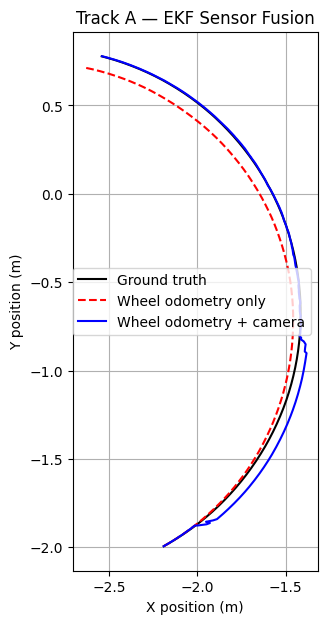

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    truth_log[:, 0],
    truth_log[:, 1],
    "k-",
    label="Ground truth"
)

ax.plot(
    odom_log[:, 0],
    odom_log[:, 1],
    "r--",
    label="Wheel odometry only"
)

ax.plot(
    camera_log[:, 0],
    camera_log[:, 1],
    "b-",
    label="Wheel odometry + camera"
)

ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_title("Track A — EKF Sensor Fusion")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.show()


In [40]:
from tb3nav.sim import Sim2D, Measurements
from tb3nav.vision import measurements_from_corners

class PlanarMuJoCoWithCamera(PlanarMuJoCoWithLiDAR):

    def __init__(self, cfg, model, data):
        super().__init__(cfg, model, data)

        # Reuse the camera model from the original ZIP
        self.camera_sim = Sim2D(
            cfg,
            x0=cfg.X0_NOMINAL,
            seed=42,
            wheel_error=0.0
        )

        self.cam = self.camera_sim.cam

    def reset(self):
        super().reset()

        if hasattr(self, "camera_sim"):
            self.camera_sim._x = self.x.copy()
            self.camera_sim.t = self.t

    def step(self, u):
        # Existing robot motion, odometry and LiDAR
        m = super().step(u)

        # Synchronise camera model with MuJoCo robot
        self.camera_sim._x = self.x.copy()
        self.camera_sim.t = self.t

        # Generate projected marker corners
        corners = self.camera_sim._camera()

        return Measurements(
            t=m.t,
            odom=m.odom,
            corners=corners,
            lidar=m.lidar
        )

print("MuJoCo camera adapter created!")


MuJoCo camera adapter created!


In [34]:
sim = PlanarMuJoCoWithCamera(cfg, model, data)

detected_ids = set()
last_m = None

for i in range(100):
    # Rotate in place to look for markers
    last_m = sim.step((0.0, 0.3))
    detected_ids.update(last_m.corners.keys())

print("=== MUJOCO SENSOR TEST ===")
print("Simulation time:", round(last_m.t, 2), "s")
print("Wheel odometry:", last_m.odom)
print("LiDAR rays:", len(last_m.lidar))
print("Detected marker IDs:", sorted(detected_ids))
print("Number of unique markers:", len(detected_ids))


NameError: name 'PlanarMuJoCoWithCamera' is not defined

In [ ]:
from tb3nav.ekf import EKFConfig, ekf_step
from tb3nav.vision import measurements_from_corners

sim.reset()

ec = EKFConfig(cfg)

xh = np.array(cfg.X0_NOMINAL, dtype=float)
P = np.diag(np.array(cfg.P0_std) ** 2)

truth_log = []
estimate_log = []
accepted_updates = 0
detected_ids = set()

for i in range(300):

    # Fixed test commands, not yet LQR
    m = sim.step((0.08, 0.08))

    detected_ids.update(m.corners.keys())

    # Convert marker corners to range/bearing
    Z = measurements_from_corners(
        cfg,
        sim.cam,
        m.corners
    )

    # EKF prediction and camera correction
    xh, P, nis = ekf_step(
        xh,
        P,
        m.odom,
        Z,
        ec
    )

    accepted_updates += sum(
        bool(entry[2]) for entry in nis
    )

    truth_log.append(sim.ground_truth())
    estimate_log.append(xh.copy())

truth_log = np.array(truth_log)
estimate_log = np.array(estimate_log)

errors = np.linalg.norm(
    truth_log[:, :2] - estimate_log[:, :2],
    axis=1
)

print("=== MUJOCO + EKF RESULTS ===")
print("Detected markers:", sorted(detected_ids))
print("Accepted camera updates:", accepted_updates)
print("Position RMSE:",
      round(np.sqrt(np.mean(errors**2)), 4), "m")
print("Final position error:",
      round(errors[-1], 4), "m")
print("Final covariance diagonal:", np.diag(P))

=== MUJOCO + EKF RESULTS ===
Detected markers: [1, 2, 6]
Accepted camera updates: 237
Position RMSE: 0.0965 m
Final position error: 0.0032 m
Final covariance diagonal: [2.01389149e-04 8.77604681e-05 2.47441750e-03]


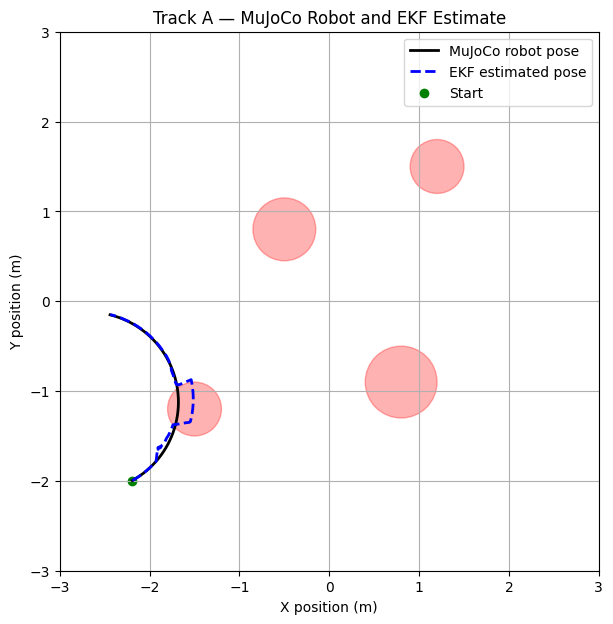

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    truth_log[:, 0],
    truth_log[:, 1],
    "k-",
    linewidth=2,
    label="MuJoCo robot pose"
)

ax.plot(
    estimate_log[:, 0],
    estimate_log[:, 1],
    "b--",
    linewidth=2,
    label="EKF estimated pose"
)

for ox, oy, radius in cfg.obstacles:
    ax.add_patch(
        plt.Circle(
            (ox, oy),
            radius,
            color="red",
            alpha=0.3
        )
    )

ax.scatter(
    cfg.X0_NOMINAL[0],
    cfg.X0_NOMINAL[1],
    color="green",
    marker="o",
    label="Start"
)

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect("equal")
ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_title("Track A — MuJoCo Robot and EKF Estimate")
ax.grid(True)
ax.legend()

plt.show()

In [ ]:
import inspect
from tb3nav.control import LQRController

print("=== LQR CONTROLLER ===")
print(inspect.getsource(LQRController))

=== LQR CONTROLLER ===
class LQRController:
    def __init__(self, cfg):
        self.cfg, self.sched = cfg, GainSchedule(cfg, integral=False)

    def reset(self):
        pass

    def step(self, e_y, e_theta, kappa, v):
        K = self.sched.K(v)
        omega = v * kappa - (K @ np.array([e_y, e_theta])).item()
        return float(np.clip(omega, -self.cfg.omega_max, self.cfg.omega_max))



In [ ]:
from tb3nav.pipeline import simulate_lqg

source = inspect.getsource(simulate_lqg)

print("=== ORIGINAL LQG PIPELINE ===")
print(source)

=== ORIGINAL LQG PIPELINE ===
def simulate_lqg(cfg=None, ctrl="lqi", seed=0, sim_kw=None, no_updates=False):
    """The EKF estimate drives the controller. x_true is kept for the log only: if it appeared in the control
    path the loop would not be LQG (see the control block below)."""
    cfg = cfg or Config()
    sim, path, clr, x_nom, P0 = _setup(cfg, seed, sim_kw or {})
    controller = _controller(cfg, ctrl); controller.reset()
    ec, cam = EKFConfig(cfg), make_camera(cfg)
    icp = ICPOdomSource(cfg, sim.lidar_angles) if cfg.odom_source == "icp" else None
    sv, sw = ((cfg.icp_sigma_v, cfg.icp_sigma_w) if icp else (cfg.ekf_sigma_v, cfg.ekf_sigma_w))
    xh, P = x_nom.copy(), P0.copy()
    log, u, idx, hold, reached = _empty_log(), (0.0, 0.0), 0, 0, False
    for k in range(int(cfg.t_max / cfg.T)):
        m = sim.step(u)                                            # robot moves, sensors are read
        odom = icp(m.lidar, m.odom)[0] if icp else m.odom          # wheel encoders

In [ ]:
from tb3nav.planner import build_reference

print("=== PLANNER FUNCTION ===")
print(inspect.signature(build_reference))

print("\n=== PATH OBJECT ===")
print("Type:", type(path))
print("Available attributes:")

for name in dir(path):
    if not name.startswith("_"):
        value = getattr(path, name)
        if callable(value):
            print(name, inspect.signature(value))
        else:
            print(name, type(value).__name__)

=== PLANNER FUNCTION ===
(cfg, start_xy, start_theta)

=== PATH OBJECT ===
Type: <class 'tb3nav.control.Path'>
Available attributes:
errors (pose, idx=0, window=120)
errors_along (X)
kappa ndarray
s ndarray
s_end float64
th ndarray
x ndarray
xy ndarray
y ndarray


In [ ]:
print("=== ADAPTER CHECK ===")

sim = PlanarMuJoCoWithCamera(cfg, model, data)

m = sim.step((0.1, 0.0))

print("Robot pose:", sim.ground_truth())
print("Odometry:", m.odom)
print("LiDAR rays:", len(m.lidar))
print("Camera detections:", len(m.corners))
print("Adapter ready!")

=== ADAPTER CHECK ===
Robot pose: [-2.19122417 -1.99520574  0.5       ]
Odometry: (0.09975736188125961, -0.005546892392229058)
LiDAR rays: 360
Camera detections: 0
Adapter ready!


In [ ]:
import numpy as np
import mujoco
import matplotlib.pyplot as plt

from tb3nav.control import LQRController
from tb3nav.ekf import EKFConfig, ekf_step
from tb3nav.vision import measurements_from_corners
from tb3nav.pipeline import speed_command, lidar_safety

print("EKF, LQR, and safety functions imported!")

EKF, LQR, and safety functions imported!


In [28]:
import numpy as np

# Initialise simulator
sim = PlanarMuJoCoWithCamera(cfg, model, data)

# Initialise EKF
ec = EKFConfig(cfg)

xh = np.array(cfg.X0_NOMINAL, dtype=float)
P = np.diag(np.array(cfg.P0_std) ** 2)

# Initialise LQR
controller = LQRController(cfg)
controller.reset()

# Generate planned path
from tb3nav.planner import build_reference

path, clearance = build_reference(
    cfg,
    np.array(cfg.X0_NOMINAL[:2]),
    cfg.X0_NOMINAL[2]
)

# Logs
truth_log = []
estimate_log = []
control_log = []
error_log = []
time_log = []

accepted_updates = 0
detected_ids = set()

u = (0.0, 0.0)
idx = 0
hold = 0
reached = False

max_steps = int(cfg.t_max / cfg.T)

for k in range(max_steps):

    # 1. Move robot and collect sensors
    m = sim.step(u)

    # 2. Camera measurements
    detected_ids.update(m.corners.keys())

    Z = measurements_from_corners(
        cfg,
        sim.cam,
        m.corners
    )

    # 3. EKF prediction and correction
    xh, P, nis = ekf_step(
        xh, P, m.odom, Z, ec
    )

    accepted_updates += sum(
        bool(entry[2]) for entry in nis
    )

    # 4. Calculate path tracking errors
    # IMPORTANT: estimated state only
    e_y, e_th, kappa, s, idx = path.errors(
        xh, idx
    )

    d_rem = path.s_end - s

    # 5. Speed command
    v = speed_command(cfg, d_rem)

    # 6. LQR steering
    omega = controller.step(
        e_y, e_th, kappa, v
    )

    # 7. LiDAR safety
    v, omega = lidar_safety(
        cfg,
        sim.lidar_angles,
        m.lidar,
        v,
        omega
    )

    # 8. Stop near docking station
    if d_rem < 0.02:
        hold += 1
        v = 0.0
        omega = 0.0

        if hold > int(1.0 / cfg.T):
            reached = True
            break
    else:
        hold = 0

    u = (v, omega)

    # 9. Evaluation logging only
    truth_log.append(sim.ground_truth())
    estimate_log.append(xh.copy())
    control_log.append(u)
    error_log.append([e_y, e_th])
    time_log.append(m.t)

truth_log = np.array(truth_log)
estimate_log = np.array(estimate_log)
control_log = np.array(control_log)
error_log = np.array(error_log)
time_log = np.array(time_log)

print("=== CLOSED-LOOP NAVIGATION RESULTS ===")
print("Reached goal:", reached)
print("Simulation time:", round(sim.t, 2), "s")
print("Detected markers:", sorted(detected_ids))
print("Accepted camera updates:", accepted_updates)

final_truth = sim.ground_truth()

position_error = np.linalg.norm(
    final_truth[:2] -
    np.array(cfg.dock_pose[:2])
)

heading_error = (
    final_truth[2] - cfg.dock_pose[2] + np.pi
) % (2 * np.pi) - np.pi

print("Final docking position error:",
      round(position_error, 4), "m")

print("Final heading error:",
      round(np.degrees(heading_error), 2),
      "degrees")


NameError: name 'PlanarMuJoCoWithCamera' is not defined

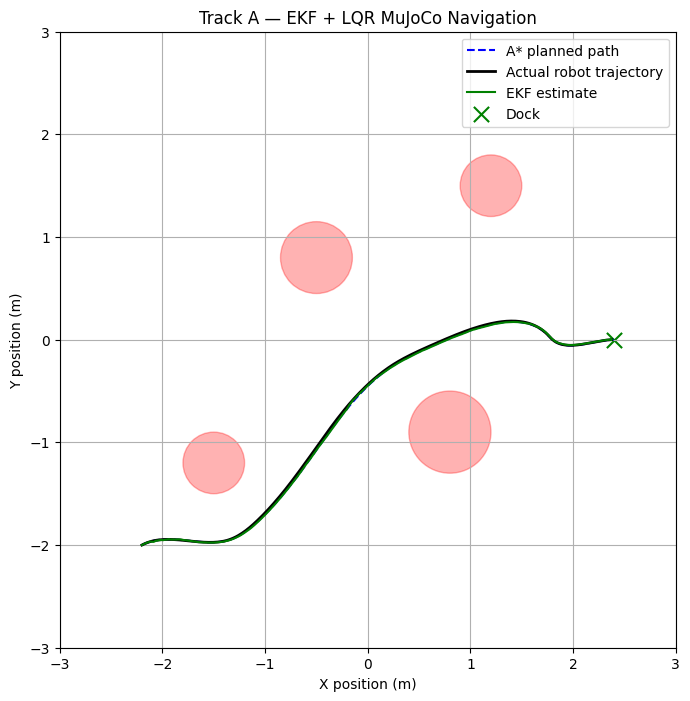

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))

# Obstacles
for ox, oy, radius in cfg.obstacles:
    ax.add_patch(
        plt.Circle(
            (ox, oy),
            radius,
            color="red",
            alpha=0.3
        )
    )

# Planned path
ax.plot(
    path.x, path.y,
    "b--",
    label="A* planned path"
)

# Actual robot trajectory
ax.plot(
    truth_log[:, 0],
    truth_log[:, 1],
    "k-",
    linewidth=2,
    label="Actual robot trajectory"
)

# EKF estimate
ax.plot(
    estimate_log[:, 0],
    estimate_log[:, 1],
    "g-",
    linewidth=1.5,
    label="EKF estimate"
)

# Dock
ax.scatter(
    cfg.dock_pose[0],
    cfg.dock_pose[1],
    marker="x",
    s=120,
    color="green",
    label="Dock"
)

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect("equal")
ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_title("Track A — EKF + LQR MuJoCo Navigation")
ax.grid(True)
ax.legend()

plt.show()

In [ ]:
# Position estimation error
pos_errors = np.linalg.norm(
    truth_log[:, :2] - estimate_log[:, :2],
    axis=1
)

pos_rmse = np.sqrt(np.mean(pos_errors**2))

# Cross-track error
cross_track_rmse = np.sqrt(
    np.mean(error_log[:, 0]**2)
)

# Obstacle clearance
min_clearance = float("inf")

for ox, oy, radius in cfg.obstacles:
    distances = np.hypot(
        truth_log[:, 0] - ox,
        truth_log[:, 1] - oy
    )

    clearance_i = (
        np.min(distances)
        - radius
        - cfg.robot_radius
    )

    min_clearance = min(
        min_clearance, clearance_i
    )

print("=== NAVIGATION PERFORMANCE ===")
print("Position estimation RMSE:",
      round(pos_rmse, 4), "m")

print("Estimated cross-track RMSE:",
      round(cross_track_rmse, 4), "m")

print("Minimum obstacle clearance:",
      round(min_clearance, 4), "m")

print("Collision-free:",
      min_clearance > 0)

print("Reached goal:", reached)

=== NAVIGATION PERFORMANCE ===
Position estimation RMSE: 0.0146 m
Estimated cross-track RMSE: 0.0037 m
Minimum obstacle clearance: 0.2871 m
Collision-free: True
Reached goal: True


In [ ]:
import numpy as np

np.savez(
    "trackA_successful_run.npz",
    truth=truth_log,
    estimate=estimate_log,
    controls=control_log,
    errors=error_log,
    time=time_log,
    planned_x=path.x,
    planned_y=path.y
)

print("Successful simulation data saved!")

Successful simulation data saved!


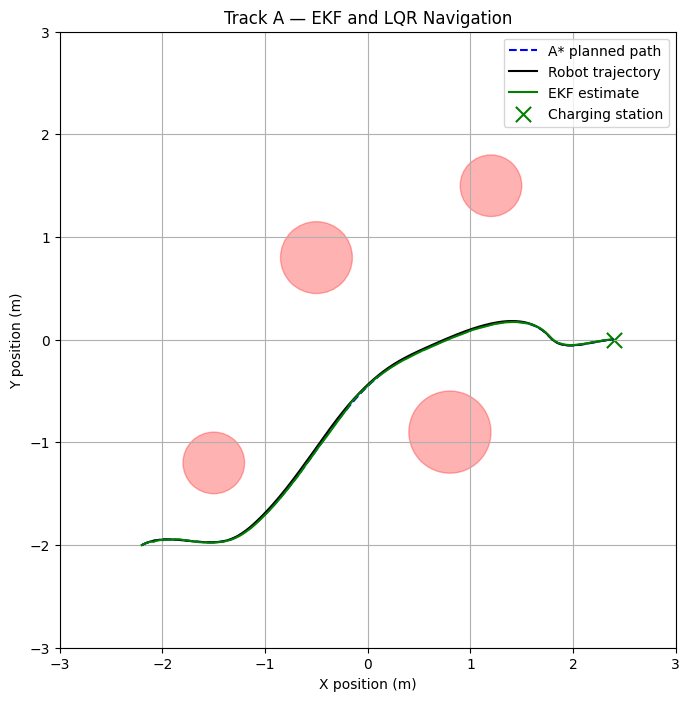

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))

for ox, oy, radius in cfg.obstacles:
    ax.add_patch(
        plt.Circle(
            (ox, oy),
            radius,
            color="red",
            alpha=0.3
        )
    )

ax.plot(
    path.x, path.y,
    "b--", label="A* planned path"
)

ax.plot(
    truth_log[:, 0],
    truth_log[:, 1],
    "k-", label="Robot trajectory"
)

ax.plot(
    estimate_log[:, 0],
    estimate_log[:, 1],
    "g-", label="EKF estimate"
)

ax.scatter(
    cfg.dock_pose[0],
    cfg.dock_pose[1],
    marker="x",
    color="green",
    s=120,
    label="Charging station"
)

ax.set_aspect("equal")
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_title("Track A — EKF and LQR Navigation")
ax.legend()
ax.grid(True)

plt.savefig(
    "trackA_navigation_results.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from google.colab import files

files.download("trackA_successful_run.npz")
files.download("trackA_navigation_results.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import mujoco

print("=== MUJOCO MODEL INFORMATION ===")

print("Number of bodies:", model.nbody)
print("Number of joints:", model.njnt)
print("Number of actuators:", model.nu)
print("Number of geometries:", model.ngeom)

print("\n=== JOINTS ===")

for i in range(model.njnt):
    name = mujoco.mj_id2name(
        model,
        mujoco.mjtObj.mjOBJ_JOINT,
        i
    )
    print(i, name)

print("\n=== ACTUATORS ===")

for i in range(model.nu):
    name = mujoco.mj_id2name(
        model,
        mujoco.mjtObj.mjOBJ_ACTUATOR,
        i
    )
    print(i, name)

print("\n=== BODIES ===")

for i in range(model.nbody):
    name = mujoco.mj_id2name(
        model,
        mujoco.mjtObj.mjOBJ_BODY,
        i
    )
    print(i, name)

=== MUJOCO MODEL INFORMATION ===
Number of bodies: 2
Number of joints: 3
Number of actuators: 0
Number of geometries: 12

=== JOINTS ===
0 x_joint
1 y_joint
2 yaw_joint

=== ACTUATORS ===

=== BODIES ===
0 world
1 robot


In [16]:
import mujoco

mujoco.mj_saveLastXML(
    "trackA_planar_backup.xml",
    model
)

print("Existing MuJoCo model saved!")

Existing MuJoCo model saved!


In [15]:
import mujoco
import numpy as np

print("=== ROBOT GEOMETRY ===")

for i in range(model.ngeom):

    name = mujoco.mj_id2name(
        model,
        mujoco.mjtObj.mjOBJ_GEOM,
        i
    )

    body_id = model.geom_bodyid[i]

    body_name = mujoco.mj_id2name(
        model,
        mujoco.mjtObj.mjOBJ_BODY,
        body_id
    )

    print(
        f"Geom {i}: {name}",
        f"| Body: {body_name}",
        f"| Type: {model.geom_type[i]}",
        f"| Size: {model.geom_size[i]}"
    )

=== ROBOT GEOMETRY ===
Geom 0: floor | Body: world | Type: 0 | Size: [3.  3.  0.1]
Geom 1: north_wall | Body: world | Type: 6 | Size: [3.   0.05 0.25]
Geom 2: south_wall | Body: world | Type: 6 | Size: [3.   0.05 0.25]
Geom 3: east_wall | Body: world | Type: 6 | Size: [0.05 3.   0.25]
Geom 4: west_wall | Body: world | Type: 6 | Size: [0.05 3.   0.25]
Geom 5: obstacle_0 | Body: world | Type: 5 | Size: [0.35 0.2  0.  ]
Geom 6: obstacle_1 | Body: world | Type: 5 | Size: [0.4 0.2 0. ]
Geom 7: obstacle_2 | Body: world | Type: 5 | Size: [0.3 0.2 0. ]
Geom 8: obstacle_3 | Body: world | Type: 5 | Size: [0.3 0.2 0. ]
Geom 9: charging_station | Body: world | Type: 6 | Size: [0.08 0.3  0.15]
Geom 10: chassis | Body: robot | Type: 5 | Size: [0.11 0.04 0.  ]
Geom 11: front | Body: robot | Type: 6 | Size: [0.025 0.02  0.005]


In [ ]:
cfg.robot_radius = 0.11
cfg.wheel_radius = 0.033
cfg.wheel_sep = 0.16

In [ ]:
print("=== ROBOT DIMENSIONS ===")

print("Robot radius:", cfg.robot_radius, "m")
print("Wheel radius:", cfg.wheel_radius, "m")
print("Wheel separation:", cfg.wheel_sep, "m")

print("\n=== CURRENT JOINT TYPES ===")

for i in range(model.njnt):

    print(
        mujoco.mj_id2name(
            model,
            mujoco.mjtObj.mjOBJ_JOINT,
            i
        ),
        model.jnt_type[i]
    )

=== ROBOT DIMENSIONS ===
Robot radius: 0.11 m
Wheel radius: 0.033 m
Wheel separation: 0.16 m

=== CURRENT JOINT TYPES ===
x_joint 2
y_joint 2
yaw_joint 3


In [17]:
import mujoco
import numpy as np

xml = """
<mujoco model="trackA_diff_drive">

  <compiler angle="radian"/>
  <option timestep="0.002" gravity="0 0 -9.81"
          integrator="implicitfast"/>

  <default>
    <geom friction="1 0.005 0.0001"
          condim="3"/>
    <joint damping="0.01"/>
  </default>

  <worldbody>

    <geom name="floor" type="plane"
          size="3 3 0.1"
          rgba="0.85 0.85 0.85 1"/>

    <!-- Room boundaries -->
    <geom name="north_wall" type="box"
          pos="0 3 0.25"
          size="3 0.05 0.25"/>

    <geom name="south_wall" type="box"
          pos="0 -3 0.25"
          size="3 0.05 0.25"/>

    <geom name="east_wall" type="box"
          pos="3 0 0.25"
          size="0.05 3 0.25"/>

    <geom name="west_wall" type="box"
          pos="-3 0 0.25"
          size="0.05 3 0.25"/>

    <!-- Obstacles -->
    <geom name="obstacle_0" type="cylinder"
          pos="-0.5 0.8 0.2"
          size="0.35 0.2"/>

    <geom name="obstacle_1" type="cylinder"
          pos="0.8 -0.9 0.2"
          size="0.4 0.2"/>

    <geom name="obstacle_2" type="cylinder"
          pos="-1.5 -1.2 0.2"
          size="0.3 0.2"/>

    <geom name="obstacle_3" type="cylinder"
          pos="1.2 1.5 0.2"
          size="0.3 0.2"/>

    <!-- Charging station: visual only -->
    <geom name="charging_station" type="box"
          pos="2.5 0 0.15"
          size="0.04 0.3 0.15"
          rgba="0.1 0.8 0.2 1"
          contype="0" conaffinity="0"/>

    <!-- Differential-drive robot -->
    <body name="robot" pos="-2.2 -2 0.085"
          euler="0 0 0.5">

      <freejoint name="base_free"/>

      <!-- Chassis -->
      <geom name="chassis" type="cylinder"
            size="0.10 0.025"
            mass="0.7"
            rgba="0.1 0.4 0.9 1"
            contype="0" conaffinity="0"/>

      <!-- Left wheel -->
      <body name="left_wheel" pos="0 0.08 -0.052">
        <joint name="left_wheel_joint"
               type="hinge"
               axis="0 1 0"/>
        <geom name="left_wheel_geom"
              type="cylinder"
              size="0.033 0.012"
              euler="1.5707963 0 0"
              mass="0.05"
              rgba="0.15 0.15 0.15 1"/>
      </body>

      <!-- Right wheel -->
      <body name="right_wheel" pos="0 -0.08 -0.052">
        <joint name="right_wheel_joint"
               type="hinge"
               axis="0 1 0"/>
        <geom name="right_wheel_geom"
              type="cylinder"
              size="0.033 0.012"
              euler="1.5707963 0 0"
              mass="0.05"
              rgba="0.15 0.15 0.15 1"/>
      </body>

      <!-- Rear support -->
      <geom name="rear_support"
            type="sphere"
            pos="-0.075 0 -0.067"
            size="0.018"
            mass="0.02"
            friction="0.01 0.001 0.0001"
            rgba="0.5 0.5 0.5 1"/>

      <!-- Forward direction indicator -->
      <geom name="front"
            type="box"
            pos="0.075 0 0.025"
            size="0.02 0.02 0.005"
            mass="0.005"
            contype="0" conaffinity="0"
            rgba="1 0.8 0 1"/>

    </body>

  </worldbody>

  <actuator>
    <velocity name="left_motor"
              joint="left_wheel_joint"
              kv="0.2"
              ctrlrange="-10 10"
              ctrllimited="true"/>

    <velocity name="right_motor"
              joint="right_wheel_joint"
              kv="0.2"
              ctrlrange="-10 10"
              ctrllimited="true"/>
  </actuator>

  <visual>
    <global offwidth="640" offheight="480"/>
  </visual>

</mujoco>
"""

with open("trackA_diff_drive.xml", "w") as f:
    f.write(xml)

model_drive = mujoco.MjModel.from_xml_string(xml)
data_drive = mujoco.MjData(model_drive)

print("=== NEW ROBOT MODEL ===")
print("Bodies:", model_drive.nbody)
print("Joints:", model_drive.njnt)
print("Actuators:", model_drive.nu)
print("Model created successfully!")


=== NEW ROBOT MODEL ===
Bodies: 4
Joints: 3
Actuators: 2
Model created successfully!


In [ ]:
mujoco.mj_resetData(model_drive, data_drive)

robot_id = mujoco.mj_name2id(
    model_drive,
    mujoco.mjtObj.mjOBJ_BODY,
    "robot"
)

heights = []
tilts = []

for i in range(2000):

    mujoco.mj_step(model_drive, data_drive)

    heights.append(
        data_drive.xpos[robot_id, 2]
    )

    # Robot's local vertical axis in world coordinates
    R = data_drive.xmat[robot_id].reshape(3, 3)
    tilt = np.degrees(
        np.arccos(np.clip(R[2, 2], -1, 1))
    )
    tilts.append(tilt)

print("=== STABILITY TEST ===")
print("Final height:",
      round(heights[-1], 4), "m")
print("Maximum tilt:",
      round(max(tilts), 2), "degrees")
print("Final tilt:",
      round(tilts[-1], 2), "degrees")


=== STABILITY TEST ===
Final height: 0.0848 m
Maximum tilt: 0.18 degrees
Final tilt: 0.18 degrees


In [ ]:
mujoco.mj_resetData(model_drive, data_drive)

left_id = mujoco.mj_name2id(
    model_drive,
    mujoco.mjtObj.mjOBJ_ACTUATOR,
    "left_motor"
)

right_id = mujoco.mj_name2id(
    model_drive,
    mujoco.mjtObj.mjOBJ_ACTUATOR,
    "right_motor"
)

start_xy = data_drive.qpos[:2].copy()

# Both wheels rotate at the same speed
data_drive.ctrl[left_id] = 4.0
data_drive.ctrl[right_id] = 4.0

positions = []
tilts = []

for i in range(3000):

    mujoco.mj_step(model_drive, data_drive)

    positions.append(
        data_drive.xpos[robot_id, :2].copy()
    )

    R = data_drive.xmat[robot_id].reshape(3, 3)

    tilts.append(
        np.degrees(
            np.arccos(np.clip(R[2, 2], -1, 1))
        )
    )

positions = np.array(positions)

print("=== FORWARD MOVEMENT TEST ===")
print("Start position:", start_xy)
print("Final position:", positions[-1])

print("Horizontal displacement:",
      round(np.linalg.norm(
          positions[-1] - start_xy
      ), 4), "m")

print("Maximum tilt:",
      round(max(tilts), 2), "degrees")


=== FORWARD MOVEMENT TEST ===
Start position: [-2.2 -2. ]
Final position: [-1.47374987 -1.61148788]
Horizontal displacement: 0.8236 m
Maximum tilt: 179.99 degrees


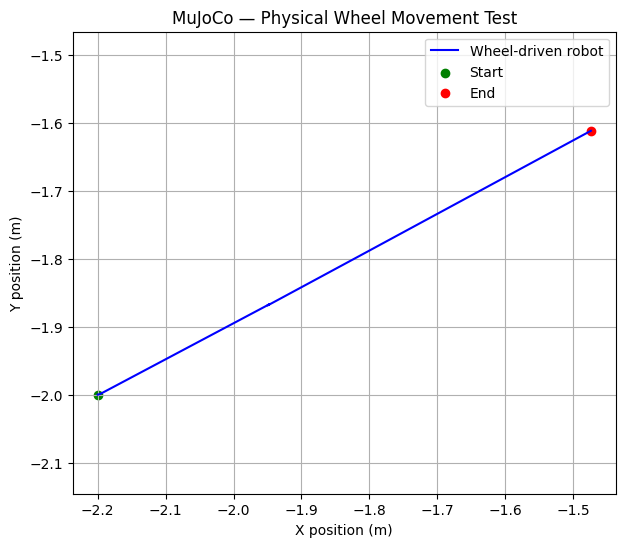

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.plot(
    positions[:, 0],
    positions[:, 1],
    "b-",
    label="Wheel-driven robot"
)

plt.scatter(
    positions[0, 0],
    positions[0, 1],
    color="green",
    label="Start"
)

plt.scatter(
    positions[-1, 0],
    positions[-1, 1],
    color="red",
    label="End"
)

plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")
plt.title("MuJoCo — Physical Wheel Movement Test")
plt.axis("equal")
plt.grid(True)
plt.legend()

plt.show()


In [18]:
import mujoco
import numpy as np

# Use the XML from Stage 16B
xml_planar = xml.replace(
    '<freejoint name="base_free"/>',
    '''
    <joint name="x_joint" type="slide"
           axis="1 0 0" damping="0.05"/>
    <joint name="y_joint" type="slide"
           axis="0 1 0" damping="0.05"/>
    <joint name="yaw_joint" type="hinge"
           axis="0 0 1" damping="0.01"/>
    '''
)

assert xml_planar != xml, "Free joint was not found!"

# Save the corrected model
with open("trackA_stable_robot.xml", "w") as f:
    f.write(xml_planar)

model_stable = mujoco.MjModel.from_xml_string(xml_planar)
data_stable = mujoco.MjData(model_stable)

print("=== STABLE ROBOT CREATED ===")
print("Bodies:", model_stable.nbody)
print("Joints:", model_stable.njnt)
print("Actuators:", model_stable.nu)
print("Position variables:", model_stable.nq)
print("Velocity variables:", model_stable.nv)

This replaces the free-moving chassis with a robot constrained to the floor plane.

The two wheel joints and actuators remain in the model.

## Step 2 — Test stability and forward movement

Run:

<CodeBlock language="python" editable>
mujoco.mj_resetData(model_stable, data_stable)

robot_id = mujoco.mj_name2id(
    model_stable,
    mujoco.mjtObj.mjOBJ_BODY,
    "robot"
)

left_id = mujoco.mj_name2id(
    model_stable,
    mujoco.mjtObj.mjOBJ_ACTUATOR,
    "left_motor"
)

right_id = mujoco.mj_name2id(
    model_stable,
    mujoco.mjtObj.mjOBJ_ACTUATOR,
    "right_motor"
)

# Drive both wheels forward
data_stable.ctrl[left_id] = 4.0
data_stable.ctrl[right_id] = 4.0

positions = []
tilts = []

for i in range(3000):
    mujoco.mj_step(model_stable, data_stable)

    positions.append(
        data_stable.xpos[robot_id, :2].copy()
    )

    R = data_stable.xmat[robot_id].reshape(3, 3)

    tilt = np.degrees(
        np.arccos(np.clip(R[2, 2], -1, 1))
    )
    tilts.append(tilt)

positions = np.array(positions)

displacement = np.linalg.norm(
    positions[-1] - positions[0]
)

print("=== STABLE MOVEMENT TEST ===")
print("Horizontal displacement:",
      round(displacement, 4), "m")
print("Maximum tilt:",
      round(max(tilts), 3), "degrees")
print("Final position:", positions[-1])

if max(tilts) < 1 and displacement > 0.1:
    print("PASS: Robot moves and remains upright!")
else:
    print("CHECK: Robot movement needs adjustment.")

SyntaxError: invalid syntax (3928271403.py, line 33)

In [19]:
import mujoco
import numpy as np

# Replace the free joint with planar joints
xml_planar = xml.replace(
    '<freejoint name="base_free"/>',
    '''
    <joint name="x_joint" type="slide"
           axis="1 0 0" damping="0.05"/>
    <joint name="y_joint" type="slide"
           axis="0 1 0" damping="0.05"/>
    <joint name="yaw_joint" type="hinge"
           axis="0 0 1" damping="0.01"/>
    '''
)

assert xml_planar != xml, "Free joint not found"

model_stable = mujoco.MjModel.from_xml_string(xml_planar)
data_stable = mujoco.MjData(model_stable)

print("=== STABLE ROBOT CREATED ===")
print("Bodies:", model_stable.nbody)
print("Joints:", model_stable.njnt)
print("Actuators:", model_stable.nu)


=== STABLE ROBOT CREATED ===
Bodies: 4
Joints: 5
Actuators: 2


In [20]:
# Reset simulation
mujoco.mj_resetData(model_stable, data_stable)
mujoco.mj_forward(model_stable, data_stable)

robot_id = mujoco.mj_name2id(
    model_stable,
    mujoco.mjtObj.mjOBJ_BODY,
    "robot"
)

left_id = mujoco.mj_name2id(
    model_stable,
    mujoco.mjtObj.mjOBJ_ACTUATOR,
    "left_motor"
)

right_id = mujoco.mj_name2id(
    model_stable,
    mujoco.mjtObj.mjOBJ_ACTUATOR,
    "right_motor"
)

# Both wheels rotate forward
data_stable.ctrl[left_id] = 4.0
data_stable.ctrl[right_id] = 4.0

positions = []
tilts = []

for i in range(3000):

    mujoco.mj_step(model_stable, data_stable)

    positions.append(
        data_stable.xpos[robot_id, :2].copy()
    )

    R = data_stable.xmat[robot_id].reshape(3, 3)

    tilt = np.degrees(
        np.arccos(np.clip(R[2, 2], -1, 1))
    )

    tilts.append(tilt)

positions = np.array(positions)

displacement = np.linalg.norm(
    positions[-1] - positions[0]
)

print("=== MOVEMENT TEST ===")
print("Displacement:", round(displacement, 4), "m")
print("Maximum tilt:", round(max(tilts), 3), "degrees")
print("Final position:", positions[-1])


=== MOVEMENT TEST ===
Displacement: 0.7613 m
Maximum tilt: 0.0 degrees
Final position: [-1.53114311 -1.63646812]


In [21]:
print("=== WHEEL CHECK ===")

for name in ["left_wheel_joint", "right_wheel_joint"]:

    jid = mujoco.mj_name2id(
        model_stable,
        mujoco.mjtObj.mjOBJ_JOINT,
        name
    )

    velocity_index = model_stable.jnt_dofadr[jid]

    print(
        name,
        round(data_stable.qvel[velocity_index], 3),
        "rad/s"
    )

if max(tilts) < 1 and displacement > 0.1:
    print("PASS: Stable wheel-driven movement")
else:
    print("CHECK: Movement needs adjustment")


=== WHEEL CHECK ===
left_wheel_joint 3.809 rad/s
right_wheel_joint 3.81 rad/s
PASS: Stable wheel-driven movement


In [44]:
import numpy as np
import mujoco

class WheelDrivenMuJoCoAdapter(PlanarMuJoCoWithCamera):

    def __init__(self, cfg, model, data):
        super().__init__(cfg, model, data)

        self.robot_id = mujoco.mj_name2id(
            model, mujoco.mjtObj.mjOBJ_BODY, "robot"
        )
        self.left_id = mujoco.mj_name2id(
            model, mujoco.mjtObj.mjOBJ_ACTUATOR, "left_motor"
        )
        self.right_id = mujoco.mj_name2id(
            model, mujoco.mjtObj.mjOBJ_ACTUATOR, "right_motor"
        )

        self.left_joint = mujoco.mj_name2id(
            model, mujoco.mjtObj.mjOBJ_JOINT, "left_wheel_joint"
        )
        self.right_joint = mujoco.mj_name2id(
            model, mujoco.mjtObj.mjOBJ_JOINT, "right_wheel_joint"
        )

        self.reset()

    def reset(self):
        # Reset physical simulation
        mujoco.mj_resetData(self.model, self.data)
        mujoco.mj_forward(self.model, self.data)

        self.t = 0.0
        self.x = np.array(self.cfg.X0_NOMINAL, dtype=float)

        if hasattr(self, "camera_sim"):
            self.camera_sim._x = self.x.copy()
            self.camera_sim.t = 0.0

    def step(self, u):
        v, omega = map(float, u)

        v = np.clip(v, -self.cfg.v_max, self.cfg.v_max)
        omega = np.clip(
            omega, -self.cfg.omega_max, self.cfg.omega_max
        )

        # Convert robot velocities to wheel velocities
        L = self.cfg.wheel_sep
        r = self.cfg.wheel_radius

        wl = (v - omega * L / 2) / r
        wr = (v + omega * L / 2) / r

        self.data.ctrl[self.left_id] = wl
        self.data.ctrl[self.right_id] = wr

        # Advance MuJoCo physics
        n = round(self.cfg.T / self.model.opt.timestep)

        for _ in range(n):
            mujoco.mj_step(self.model, self.data)

        # Read actual robot pose from MuJoCo
        p = self.data.xpos[self.robot_id]

        R = self.data.xmat[self.robot_id].reshape(3, 3)
        theta = np.arctan2(R[1, 0], R[0, 0])

        self.x = np.array([p[0], p[1], theta])
        self.t = self.data.time

        # Virtual wheel odometry from joint velocities
        li = self.model.jnt_dofadr[self.left_joint]
        ri = self.model.jnt_dofadr[self.right_joint]

        wl_measured = self.data.qvel[li]
        wr_measured = self.data.qvel[ri]

        v_odom = r * (wl_measured + wr_measured) / 2
        w_odom = r * (wr_measured - wl_measured) / L

        odom = (v_odom, w_odom)

        # Existing geometric LiDAR
        lidar = simulate_lidar(
            self.model, self.data, self.cfg, self.x
        )

        # Existing geometric camera
        self.camera_sim._x = self.x.copy()
        self.camera_sim.t = self.t
        corners = self.camera_sim._camera()

        return Measurements(
            t=self.t,
            odom=odom,
            corners=corners,
            lidar=lidar
        )

    def ground_truth(self):
        return self.x.copy()

print("Wheel-driven MuJoCo adapter created!")

Wheel-driven MuJoCo adapter created!


In [45]:
sim_drive = WheelDrivenMuJoCoAdapter(
    cfg, model_stable, data_stable
)

print("=== WHEEL-DRIVEN ADAPTER TEST ===")

for i in range(30):
    m = sim_drive.step((0.12, 0.0))

print("Simulation time:", round(m.t, 2), "s")
print("Robot pose:", sim_drive.ground_truth())
print("Wheel odometry:", m.odom)
print("LiDAR rays:", len(m.lidar))
print("Camera detections:", len(m.corners))

=== WHEEL-DRIVEN ADAPTER TEST ===
Simulation time: 3.0 s
Robot pose: [-1.88777311 -1.83067273  0.49769458]
Wheel odometry: (np.float64(0.11425905018923177), np.float64(0.001048934559978526))
LiDAR rays: 360
Camera detections: 1


In [46]:
sim_drive.reset()

start = sim_drive.ground_truth()

for i in range(30):
    m = sim_drive.step((0.0, 0.5))

end = sim_drive.ground_truth()

heading_change = (
    end[2] - start[2] + np.pi
) % (2 * np.pi) - np.pi

print("=== TURNING TEST ===")
print("Start heading:", round(np.degrees(start[2]), 2))
print("End heading:", round(np.degrees(end[2]), 2))
print("Heading change:",
      round(np.degrees(heading_change), 2), "degrees")
print("Wheel odometry:", m.odom)


=== TURNING TEST ===
Start heading: 28.65
End heading: 113.12
Heading change: 84.47 degrees
Wheel odometry: (np.float64(1.7405731711718333e-05), np.float64(0.4741201038837448))


In [55]:
import numpy as np
import matplotlib.pyplot as plt

from tb3nav.ekf import EKFConfig, ekf_step
from tb3nav.vision import measurements_from_corners
from tb3nav.control import LQRController
from tb3nav.planner import build_reference
from tb3nav.pipeline import speed_command, lidar_safety

# Initialise wheel-driven MuJoCo robot
sim = WheelDrivenMuJoCoAdapter(
    cfg, model_stable, data_stable
)

# Initialise EKF
ec = EKFConfig(cfg)

xh = np.array(cfg.X0_NOMINAL, dtype=float)
P = np.diag(np.array(cfg.P0_std)**2)

# Initialise controller
controller = LQRController(cfg)
controller.reset()

# Generate collision-free reference path
path, clearance = build_reference(
    cfg,
    np.array(cfg.X0_NOMINAL[:2]),
    cfg.X0_NOMINAL[2]
)

# Simulation variables
u = (0.0, 0.0)
idx = 0
hold = 0
reached = False

true_log = []
est_log = []
time_log = []
control_log = []
marker_log = []

# Main simulation loop
for k in range(int(cfg.t_max / cfg.T)):

    # Move robot using MuJoCo wheel physics
    m = sim.step(u)

    # Camera marker measurements
    Z = measurements_from_corners(
        cfg, sim.cam, m.corners
    )

    # EKF estimates position and heading
    xh, P, nis = ekf_step(
        xh, P, m.odom, Z, ec
    )

    # Path-following errors use estimated state
    e_y, e_th, kappa, s, idx = path.errors(
        xh, idx
    )

    d_rem = path.s_end - s

    # LQR controller
    v = speed_command(cfg, d_rem)
    omega = controller.step(
        e_y, e_th, kappa, v
    )

    # LiDAR obstacle avoidance
    v, omega = lidar_safety(
        cfg,
        sim.lidar_angles,
        m.lidar,
        v,
        omega
    )

    # Stop when the path is completed
    if d_rem < 0.02:
        hold += 1
        v, omega = 0.0, 0.0

        if hold > 10:
            reached = True
    else:
        hold = 0

    # Store commanded velocities
    u = (v, omega)

    # Ground truth used for evaluation only
    true_log.append(sim.ground_truth())
    est_log.append(xh.copy())
    time_log.append(m.t)
    control_log.append(u)
    marker_log.append(len(m.corners))

    if reached:
        break

# Convert logs to arrays
true_log = np.array(true_log)
est_log = np.array(est_log)
time_log = np.array(time_log)
control_log = np.array(control_log)

# Final errors
dock = np.array(cfg.dock_pose)

position_error = np.linalg.norm(
    true_log[-1, :2] - dock[:2]
)

heading_error = (
    true_log[-1, 2] - dock[2] + np.pi
) % (2 * np.pi) - np.pi

estimate_rmse = np.sqrt(
    np.mean(
        np.sum(
            (true_log[:, :2] - est_log[:, :2])**2,
            axis=1
        )
    )
)

print("=== WHEEL-DRIVEN NAVIGATION RESULTS ===")
print("Reached path end:", reached)
print("Simulation time:", round(time_log[-1], 2), "s")
print("Final true pose:", true_log[-1])
print("Final estimated pose:", est_log[-1])
print("Docking position error:",
      round(position_error, 4), "m")
print("Docking heading error:",
      round(np.degrees(heading_error), 2), "degrees")
print("Position estimation RMSE:",
      round(estimate_rmse, 4), "m")
print("Camera detections:", sum(marker_log))


=== WHEEL-DRIVEN NAVIGATION RESULTS ===
Reached path end: True
Simulation time: 45.4 s
Final true pose: [2.37305665e+00 2.33015154e-03 4.32887010e-02]
Final estimated pose: [2.37549298 0.00256865 0.04971326]
Docking position error: 0.027 m
Docking heading error: 2.48 degrees
Position estimation RMSE: 0.0177 m
Camera detections: 572


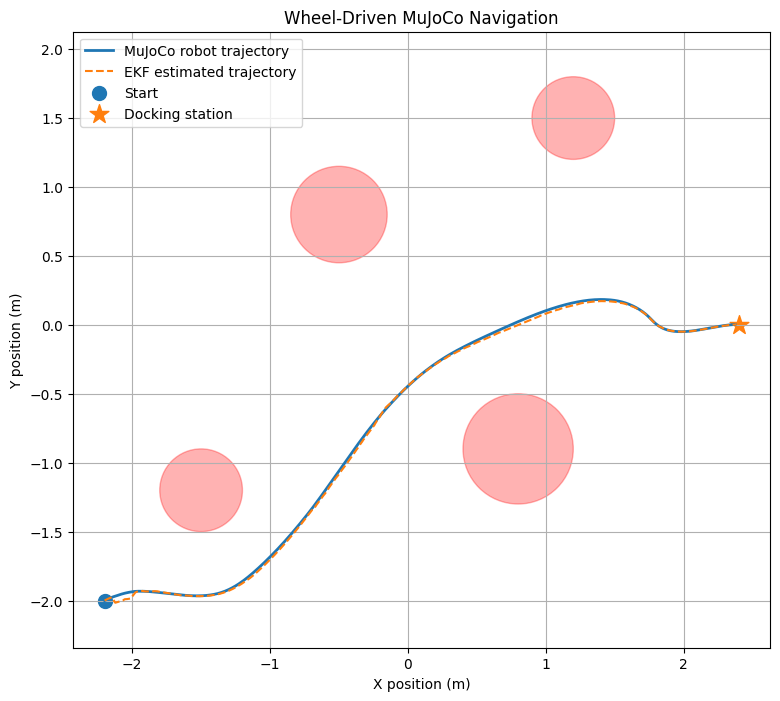

In [56]:
plt.figure(figsize=(9, 8))

# Actual robot trajectory
plt.plot(
    true_log[:, 0],
    true_log[:, 1],
    label="MuJoCo robot trajectory",
    linewidth=2
)

# EKF estimated trajectory
plt.plot(
    est_log[:, 0],
    est_log[:, 1],
    "--",
    label="EKF estimated trajectory",
    linewidth=1.5
)

# Obstacles
for ox, oy, radius in cfg.obstacles:
    circle = plt.Circle(
        (ox, oy),
        radius,
        color="red",
        alpha=0.3
    )
    plt.gca().add_patch(circle)

# Start and docking positions
plt.scatter(
    cfg.X0_NOMINAL[0],
    cfg.X0_NOMINAL[1],
    marker="o",
    s=100,
    label="Start"
)

plt.scatter(
    cfg.dock_pose[0],
    cfg.dock_pose[1],
    marker="*",
    s=200,
    label="Docking station"
)

plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")
plt.title("Wheel-Driven MuJoCo Navigation")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

In [57]:
print("=== NAVIGATION CHECKLIST ===")

checks = {
    "Path completed": reached,
    "Docking position error < 0.15 m":
        position_error < 0.15,
    "Docking heading error < 10 degrees":
        abs(np.degrees(heading_error)) < 10,
    "EKF position RMSE < 0.15 m":
        estimate_rmse < 0.15,
    "Camera measurements received":
        sum(marker_log) > 0,
    "Robot travelled":
        np.linalg.norm(
            true_log[-1, :2] - true_log[0, :2]
        ) > 1.0
}

for name, passed in checks.items():
    print(
        ("PASS" if passed else "CHECK"),
        "-",
        name
    )

print()
print(
    "Checks passed:",
    sum(checks.values()),
    "/",
    len(checks)
)


=== NAVIGATION CHECKLIST ===
PASS - Path completed
PASS - Docking position error < 0.15 m
PASS - Docking heading error < 10 degrees
PASS - EKF position RMSE < 0.15 m
PASS - Camera measurements received
PASS - Robot travelled

Checks passed: 6 / 6


Detected marker IDs: [[0]]


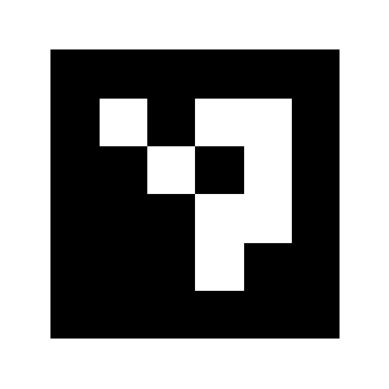

In [58]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

aruco = cv2.aruco
dictionary = aruco.getPredefinedDictionary(
    aruco.DICT_4X4_50
)

marker_id = 0
marker = aruco.generateImageMarker(
    dictionary, marker_id, 200
)

# Add white margin for reliable detection
image = np.full((256, 256), 255, dtype=np.uint8)
image[28:228, 28:228] = marker

cv2.imwrite("aruco_marker.png", image)

detector = aruco.ArucoDetector(
    dictionary,
    aruco.DetectorParameters()
)

corners, ids, rejected = detector.detectMarkers(image)

print("Detected marker IDs:", ids)

plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()


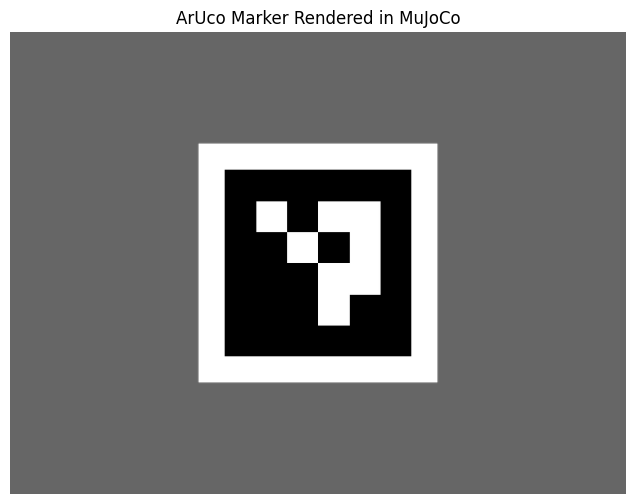

In [59]:
import mujoco
import numpy as np
import matplotlib.pyplot as plt
import cv2

marker_xml = """
<mujoco model="aruco_camera_demo">
    <option timestep="0.002"/>
    <visual>
        <headlight ambient="1 1 1"
                   diffuse="0 0 0"
                   specular="0 0 0"/>
    </visual>
    <asset>
        <texture name="marker_texture"
                 type="2d"
                 file="aruco_marker.png"/>
        <material name="marker_material"
                  texture="marker_texture"
                  texuniform="false"
                  emission="1"/>
    </asset>
    <worldbody>
        <geom name="background"
              type="plane"
              size="2 2 0.1"
              rgba="0.4 0.4 0.4 1"
              pos="0 0 -0.02"/>

        <geom name="marker"
              type="plane"
              size="0.15 0.15 0.001"
              material="marker_material"
              pos="0 0 0"/>

        <camera name="marker_camera"
                pos="0 0 0.7"
                xyaxes="1 0 0 0 1 0"
                fovy="45"/>
    </worldbody>
</mujoco>
"""

# Load the texture from the current Colab directory
model_marker = mujoco.MjModel.from_xml_string(
    marker_xml,
    assets={"aruco_marker.png":
            open("aruco_marker.png", "rb").read()}
)

data_marker = mujoco.MjData(model_marker)
mujoco.mj_forward(model_marker, data_marker)

renderer = mujoco.Renderer(
    model_marker, height=480, width=640
)

renderer.update_scene(
    data_marker, camera="marker_camera"
)

rendered = renderer.render().copy()

plt.figure(figsize=(8, 6))
plt.imshow(rendered)
plt.title("ArUco Marker Rendered in MuJoCo")
plt.axis("off")
plt.show()


=== MUJOCO CAMERA TEST ===
Detected IDs: [0]
PASS: ArUco detected in rendered image


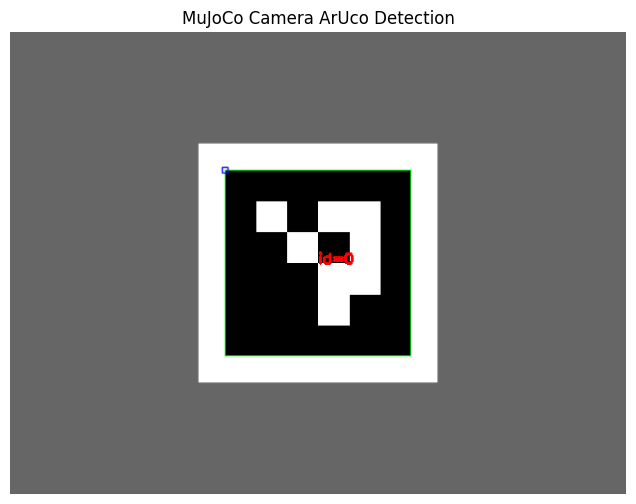

In [60]:
gray = cv2.cvtColor(
    rendered, cv2.COLOR_RGB2GRAY
)

corners, ids, rejected = detector.detectMarkers(gray)

print("=== MUJOCO CAMERA TEST ===")
print(
    "Detected IDs:",
    ids.flatten().tolist() if ids is not None else []
)

annotated = rendered.copy()

if ids is not None:
    cv2.aruco.drawDetectedMarkers(
        annotated, corners, ids
    )
    print("PASS: ArUco detected in rendered image")
else:
    print("CHECK: Marker not detected")

plt.figure(figsize=(8, 6))
plt.imshow(annotated)
plt.title("MuJoCo Camera ArUco Detection")
plt.axis("off")
plt.show()

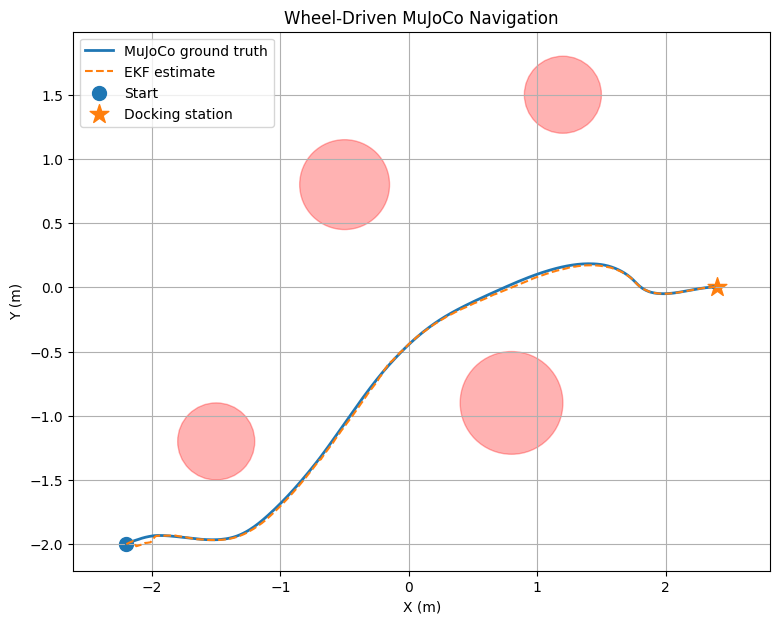

Results and figures saved successfully!


In [61]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("TrackA_Submission", exist_ok=True)

# Save navigation data
np.savez(
    "TrackA_Submission/navigation_data.npz",
    true_pose=true_log,
    estimated_pose=est_log,
    time=time_log,
    commands=control_log
)

# Save performance results
results = {
    "reached_path_end": bool(reached),
    "simulation_time_s": float(time_log[-1]),
    "docking_position_error_m": float(position_error),
    "docking_heading_error_deg": float(
        np.degrees(heading_error)
    ),
    "ekf_position_rmse_m": float(estimate_rmse),
    "camera_measurements": int(sum(marker_log))
}

with open(
    "TrackA_Submission/results.json", "w"
) as f:
    json.dump(results, f, indent=4)

# Save navigation trajectory
fig, ax = plt.subplots(figsize=(9, 7))

ax.plot(
    true_log[:, 0], true_log[:, 1],
    label="MuJoCo ground truth", linewidth=2
)

ax.plot(
    est_log[:, 0], est_log[:, 1],
    "--", label="EKF estimate"
)

for ox, oy, radius in cfg.obstacles:
    ax.add_patch(
        plt.Circle(
            (ox, oy), radius,
            color="red", alpha=0.3
        )
    )

ax.scatter(
    cfg.X0_NOMINAL[0],
    cfg.X0_NOMINAL[1],
    s=100, label="Start"
)

ax.scatter(
    cfg.dock_pose[0],
    cfg.dock_pose[1],
    marker="*", s=200,
    label="Docking station"
)

ax.set(
    xlabel="X (m)",
    ylabel="Y (m)",
    title="Wheel-Driven MuJoCo Navigation"
)

ax.axis("equal")
ax.grid(True)
ax.legend()

fig.savefig(
    "TrackA_Submission/navigation.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Save camera evidence
cv2.imwrite(
    "TrackA_Submission/aruco_detection.png",
    cv2.cvtColor(
        annotated, cv2.COLOR_RGB2BGR
    )
)

print("Results and figures saved successfully!")

In [62]:
from matplotlib.animation import FuncAnimation, FFMpegWriter

fig, ax = plt.subplots(figsize=(8, 7))

for ox, oy, radius in cfg.obstacles:
    ax.add_patch(
        plt.Circle(
            (ox, oy), radius,
            color="red", alpha=0.3
        )
    )

ax.plot(
    cfg.dock_pose[0],
    cfg.dock_pose[1],
    "g*", markersize=16,
    label="Dock"
)

actual_line, = ax.plot(
    [], [], "b-", linewidth=2,
    label="Actual"
)

estimated_line, = ax.plot(
    [], [], "orange", linestyle="--",
    label="EKF"
)

robot_dot, = ax.plot(
    [], [], "bo", markersize=8
)

ax.set_xlim(-2.7, 2.8)
ax.set_ylim(-2.5, 2.5)
ax.set_aspect("equal")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.grid(True)
ax.legend()

# Replay at approximately 4x simulation speed
indices = np.unique(
    np.linspace(
        0, len(true_log) - 1, 180
    ).astype(int)
)

def update(frame):
    i = indices[frame]

    actual_line.set_data(
        true_log[:i+1, 0],
        true_log[:i+1, 1]
    )

    estimated_line.set_data(
        est_log[:i+1, 0],
        est_log[:i+1, 1]
    )

    robot_dot.set_data(
        [true_log[i, 0]],
        [true_log[i, 1]]
    )

    ax.set_title(
        f"Wheel-Driven Navigation: "
        f"{time_log[i]:.1f} s"
    )

    return actual_line, estimated_line, robot_dot

animation = FuncAnimation(
    fig, update,
    frames=len(indices),
    interval=100,
    blit=False
)

animation.save(
    "TrackA_Submission/navigation_replay.mp4",
    writer=FFMpegWriter(fps=15),
    dpi=100
)

plt.close(fig)

print("Navigation replay video saved!")

Navigation replay video saved!


In [63]:
import shutil
from google.colab import files

shutil.make_archive(
    "TrackA_Submission",
    "zip",
    "TrackA_Submission"
)

files.download("TrackA_Submission.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import os

print("=== CURRENT PROJECT FILES ===")

for root, dirs, files in os.walk("."):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", ".ipynb_checkpoints"]
    ]

    if root.count(os.sep) > 2:
        dirs[:] = []
        continue

    for name in files:
        if name.endswith((".py", ".xml", ".png", ".mp4", ".json", ".npz", ".ipynb")):
            print(os.path.join(root, name))

=== CURRENT PROJECT FILES ===
./.config/.last_update_check.json
./sample_data/anscombe.json


In [2]:
import os
import shutil

project_dir = "UTS-41014-TrackA"
os.makedirs(project_dir, exist_ok=True)

# Copy your navigation package
if os.path.isdir("tb3nav"):
    shutil.copytree(
        "tb3nav",
        os.path.join(project_dir, "tb3nav"),
        dirs_exist_ok=True,
        ignore=shutil.ignore_patterns(
            "__pycache__", "*.pyc"
        )
    )

# Copy saved results and figures
if os.path.isdir("TrackA_Submission"):
    shutil.copytree(
        "TrackA_Submission",
        os.path.join(project_dir, "results"),
        dirs_exist_ok=True
    )

# Copy MuJoCo model
if os.path.isfile("trackA_stable_robot.xml"):
    shutil.copy2(
        "trackA_stable_robot.xml",
        project_dir
    )

# Copy ArUco marker
if os.path.isfile("aruco_marker.png"):
    shutil.copy2(
        "aruco_marker.png",
        project_dir
    )

print("=== GITHUB PROJECT PACKAGE ===")

for root, dirs, files in os.walk(project_dir):
    for filename in files:
        print(os.path.join(root, filename))


=== GITHUB PROJECT PACKAGE ===
